# YelpData Review Analysis
Aman J Upadhyay

# 1. Overall Project Objectives  

Yelp is an application to provide the platform for customers to write reviews and provide a star-rating. A research indicates that a one-star increase led to 59% increase in revenue of independent restaurants. Therefore, we see great potential of Yelp dataset as a valuable insights repository.

The main purpose of our project is to conduct thorough analysis on 7 different cuisine types of restaurants which are Korean, Japanese, Chinese, Vietnamese,Thai, French and Italian, figure out what makes a good restaurant and what concerns customers, and then make recommendations of the future improvement and profit growth. Specifically, we will mainly analyze customers' reviews and figure out reasons why customers love or dislike the restaurant. For example, there may be great reviews primarily due to the friendly service, or negative reviews about high price. Meanwhile, we will also compare among those 7 different cuisine types and figure out differences from reviews and gain valuable insights to make customized recommendations to different types of restaurants.

# 2. Description of Data

The Yelp dataset is downloaded from https://business.yelp.com/data/resources/open-dataset/ . The subset of the Yelp dataset comprises 10,000 business records and 10,000 user reviews. Business metadata includes key identifiers and location data, while reviews capture sentiment and engagement metrics. Initial preprocessing involves handling missing address and postal codes, date conversion, and verifying key relationships for downstream modeling and visualization tasks.. we will focus on two tables which are business table and review table. Attributes of business table are as following:

* business_id: ID of the business
* name: name of the business
* address: address of the business
* city: city of the business
* state: state of the business
* postal_code: postal code of the business
* latitude: latitude of the business
* longitude: longitude of the business
* stars: average rating of the business
* review_count: number of reviews received
* is_open: 1 if the business is open, 0 therwise
* categories: multiple categories of the business

Attribues of review table are as following:
* review_id: ID of the review
* user_id: ID of the user
* business_id: ID of the business
* stars: ratings of the business
* date: review date
* text: review from the user
* useful: number of users who vote a review as usefull
* funny: number of users who vote a review as funny
* cool: number of users who vote a review as cool

# 3. Direction of Analysis


**Exploratory data  analysis**
* Count the number of each cuisine type of restaurants
* Count the number of reviews in each cuisine type of restaurants
* Visualize the distribution of restaurants according to the ratings and cuisine types of restaurants.

**Review Analysis**
* Clean the category column in business table into different cuisine types of restaurants and find out how the reviews can help this type of restaurants improve in the future.
* Refer the business id in business table to review table, collect all the reviews of this type of restaurants and perform sentiment analysis to analyze frequent words in positive and negative reviews.
* Implement SVM model to get relatively positive and negative words and get score of each word.
* Get top 10 positive words and negative words in each cuisine type of restaurants in order to figure out the reason of high score and low score.
* Compare among different types of restaurants to figure out the advantages and disadvantages, then we can generate a series of recommendations to this type of restaurants for the future development.
* Overall, recommendations may have different topics which is but not limited to service, food, or decoration, etc. Our analysis is generally based on review words which we can tell from such as rude, overpriced, and slow to find out which aspect in this type of restaurants that they could improve.

# 4.  Summary of Progress

**Selection and Filtering**
* Filter out 50 states of US.  
* Filter out all restaurants of US.

**Cleaning**
* Categorize all restaurants by cuisine type using the matching keywords.  
* Delete all records with null category.
* Remove quotation marks of name and address columns.  
* Label restaurants above rating of 4 as positive, below rating 3 label as negative, label rating 3 as neural.  
* Drop rows with neural label.
* Apply 'bag of words': the frequencies of various words appeared in each review as features and conduct SVM model to get score of each word.  

**Reshaping and Reindexing**
* Reindex the data frame.  
* Build a new column to input the new category name and delete the previous column.  
* Convert array to dataframe.

**Visualization**
* Visualize the distribution of restaurants and reviews by category using seaborn.  
* Visualize the distribution of restaurants and reviews by rating.
* Visualize top 10 negative words and positive words in each cuisine type.

**Manipulation**
* Get a 'polarity score' (a value that reflects the polarity of sentiment) towards each restaurant category, the sentiment score of each word was first multiplied by its frequency, and then normalized by the total number of reviews for the specific category of restaurants.   

**Merging multiple data sets**
* Merge business table and review.  

# 5. Progress in Coding

## Data Preparation

In [1]:
!pip uninstall -y gensim numpy
!pip cache purge


Found existing installation: numpy 1.24.4
Uninstalling numpy-1.24.4:
  Successfully uninstalled numpy-1.24.4
Files removed: 12


In [2]:
!pip install numpy==1.24.4
!pip install gensim==4.3.1


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.3/17.3 MB 56.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
jax 0.5.2 requires numpy>=1.25, but you have numpy 1.24.4 which is incompatible.
jax 0.5.2 requires scipy>=1.11.1, but you have scipy 1.10.1 which is incompatible.
blosc2 3.3.4 requires numpy>=1.26, but you have numpy 1.24.4 which is incompatible.
thinc 8.3.6 requires numpy<3.0.0,>=2.0.0, but you have numpy 1.24.4 which is incompatible.
treescope 0.1.9 requires numpy>=1.25.2, but you have numpy 1.24.4 which is incompatible.
xarray-einstats 0.9.0 requires numpy>=1.25, but you have numpy 1.24.4 which is incompatible.
xarray-einstats 0.9.0 requires scipy>=1.11, but you have scipy 1.10.1 which is incompatible.
jaxlib 0.5.1 requires numpy>=1.25, but you have numpy 1.24.4 which is incompatible.
jaxlib 0.5.1 requires scipy>=1.11.1, but you hav

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 26.6/26.6 MB 42.7 MB/s eta 0:00:00


In [3]:
!pip install virtualenv
!virtualenv venv
!source venv/bin/activate


created virtual environment CPython3.11.12.final.0-64 in 461ms
  creator CPython3Posix(dest=/content/venv, clear=False, no_vcs_ignore=False, global=False)
  seeder FromAppData(download=False, pip=bundle, setuptools=bundle, via=copy, app_data_dir=/root/.local/share/virtualenv)
    added seed packages: pip==25.1.1, setuptools==80.3.1
  activators BashActivator,CShellActivator,FishActivator,NushellActivator,PowerShellActivator,PythonActivator


In [4]:
import pandas as pd
import seaborn as sns
%pylab inline
pd.set_option('display.max_columns',None)
pd.options.display.max_seq_items = 2000
pd.options.display.max_rows = 2000
pd.set_option('display.max_rows', 500)
pd.set_option('display.max_columns', 500)
pd.set_option('display.width', 1000)
import requests, re
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import nltk
import string, itertools
from collections import Counter, defaultdict
from nltk.text import Text
from nltk.probability import FreqDist
from nltk.tokenize import word_tokenize, sent_tokenize, regexp_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
#from gensim.corpora.dictionary import Dictionary
#from gensim.models.tfidfmodel import TfidfModel
from sklearn.cluster import KMeans
from wordcloud import WordCloud

Populating the interactive namespace from numpy and matplotlib


### Clean Yelp_business dataset

In [5]:
business = pd.read_csv("/content/filtered_yelp_business_2018_to_2023.csv")
reviews = pd.read_csv("/content/filtered_yelp_reviews_2018_2023.csv")

In [6]:
business.head()

,business_id,name,address,city,state,postal_code,latitude,longitude,stars,review_count,is_open,attributes,categories
0,Pns2l4eNsfO8kk83dixA6A,"Abby Rappoport, LAC, CMQ","1616 Chapala St, Ste 2",Santa Barbara,CA,93101,34.426679,-119.711197,5.0,7,0,{'ByAppointmentOnly': 'True'},"Doctors, Traditional Chinese Medicine, Naturop..."
1,mpf3x-BjTdTEA3yCZrAYPw,The UPS Store,87 Grasso Plaza Shopping Center,Affton,MO,63123,38.551126,-90.335695,3.0,15,1,{'BusinessAcceptsCreditCards': 'True'},"Shipping Centers, Local Services, Notaries, Ma..."
2,tUFrWirKiKi_TAnsVWINQQ,Target,5255 E Broadway Blvd,Tucson,AZ,85711,32.223236,-110.880452,3.5,22,0,"{'BikeParking': 'True', 'BusinessAcceptsCredit...","Department Stores, Shopping, Fashion, Home & G..."
3,MTSW4McQd7CbVtyjqoe9mw,St Honore Pastries,935 Race St,Philadelphia,PA,19107,39.955505,-75.155564,4.0,80,1,"{'RestaurantsDelivery': 'False', 'OutdoorSeati...","Restaurants, Food, Bubble Tea, Coffee & Tea, B..."
4,mWMc6_wTdE0EUBKIGXDVfA,Perkiomen Valley Brewery,101 Walnut St,Green Lane,PA,18054,40.338183,-75.471659,4.5,13,1,"{'BusinessAcceptsCreditCards': 'True', 'Wheelc...","Brewpubs, Breweries, Food"


In [7]:
reviews.head()

,review_id,user_id,business_id,stars,useful,funny,cool,text,date
0,KU_O5udG6zpxOg-VcAEodg,mh_-eMZ6K5RLWhZyISBhwA,XQfwVwDr-v0ZS3_CbbE5Xw,3,0,0,0,"If you decide to eat here, just be aware it is...",2018-07-07 22:09:11
1,lUUhg8ltDsUZ9h0xnwY4Dg,RreNy--tOmXMl1en0wiBOg,cPepkJeRMtHapc_b2Oe_dw,4,1,0,1,I was really between 3 and 4 stars for this on...,2018-07-17 03:30:07
2,JBWZmBy69VMggxj3eYn17Q,aFa96pz67TwOFu4Weq5Agg,kq5Ghhh14r-eCxlVmlyd8w,5,0,0,0,My boyfriend and I tried this deli for the fir...,2018-08-23 21:39:38
3,E9AB7V4z8xrt2uPF7T55FQ,iYY5Ii1LGpZCpXFkHlMefw,Zx7n8mdt8OzLRXVzolXNhQ,5,0,0,0,Amazing biscuits and (fill in the blank). Grea...,2018-04-27 23:03:21
4,A4n4YaE-owOVgTQcrVqHUw,S7bjj-L07JuRr-tpX1UZLw,I6L0Zxi5Ww0zEWSAVgngeQ,4,0,0,0,The cafe was extremely cute. We came at 8am an...,2018-07-07 20:50:12


In [8]:
business.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   business_id   10000 non-null  object 
 1   name          10000 non-null  object 
 2   address       9677 non-null   object 
 3   city          10000 non-null  object 
 4   state         10000 non-null  object 
 5   postal_code   9997 non-null   object 
 6   latitude      10000 non-null  float64
 7   longitude     10000 non-null  float64
 8   stars         10000 non-null  float64
 9   review_count  10000 non-null  int64  
 10  is_open       10000 non-null  int64  
 11  attributes    10000 non-null  object 
 12  categories    10000 non-null  object 
dtypes: float64(3), int64(2), object(8)
memory usage: 1015.8+ KB


In [9]:
reviews.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   review_id    10000 non-null  object
 1   user_id      10000 non-null  object
 2   business_id  10000 non-null  object
 3   stars        10000 non-null  int64 
 4   useful       10000 non-null  int64 
 5   funny        10000 non-null  int64 
 6   cool         10000 non-null  int64 
 7   text         10000 non-null  object
 8   date         10000 non-null  object
dtypes: int64(4), object(5)
memory usage: 703.3+ KB


In [10]:
business.shape

(10000, 13)

In [11]:
reviews.shape

(10000, 9)

In [12]:
business.isnull().sum()

,0
business_id,0
name,0
address,323
city,0
state,0
postal_code,3
latitude,0
longitude,0
stars,0
review_count,0


In [13]:
business['address'].fillna('Unknown', inplace=True)
business['postal_code'].fillna('00000', inplace=True)



<ipython-input-13-ef68bb5ed681>:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  business['address'].fillna('Unknown', inplace=True)
<ipython-input-13-ef68bb5ed681>:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try u

In [14]:
business.isnull().sum()

,0
business_id,0
name,0
address,0
city,0
state,0
postal_code,0
latitude,0
longitude,0
stars,0
review_count,0


In [15]:
reviews.isnull().sum()

,0
review_id,0
user_id,0
business_id,0
stars,0
useful,0
funny,0
cool,0
text,0
date,0


In [16]:
business.duplicated().sum()

0

In [17]:
business.shape

(10000, 13)

In [18]:
reviews.shape

(10000, 9)

In [19]:
business.state.unique()

array(['CA', 'MO', 'AZ', 'PA', 'TN', 'FL', 'IN', 'LA', 'AB', 'NV', 'ID',
       'DE', 'IL', 'NJ', 'NC', 'CO'], dtype=object)

In [20]:
business.city.unique()

array(['Santa Barbara', 'Affton', 'Tucson', 'Philadelphia', 'Green Lane',
       'Ashland City', 'Brentwood', 'St. Petersburg', 'Nashville',
       "Land O' Lakes", 'Tampa Bay', 'Indianapolis', 'Clearwater',
       'Largo', 'New Orleans', 'Kenner', 'Edmonton', 'Reno', 'Newtown',
       'White House', 'Boise', 'Paoli', 'Ardmore', 'Exton', 'Wilmington',
       'Edwardsville', 'Sparks', 'Alton', 'Cherry Hill', 'Bala Cynwyd',
       'Springfield', 'Belleville', 'Carmel', 'Tampa', 'Kennett Square',
       'Plymouth Meeting', 'Harvey', 'West Chester', 'Meridian', 'Hudson',
       'Fernley', 'Williamstown', 'Pinellas Park', 'Glenolden',
       'Wesley Chapel', 'Fishers', 'Burlington', 'Troy', 'Camden',
       'Plainfield', 'Bensalem', 'Maplewood', 'Saint Louis',
       'Fairview Heights', 'Oro Valley', 'Treasure Island', 'Southampton',
       'Chalfont', 'Willow Grove', 'Voorhees', 'Tarpon Springs',
       'Blue Bell', 'Metairie', 'Woodbury', 'Brownsburg', 'Norristown',
       'Land O Lakes',

In [21]:
# Step 1: Remove double quotes from columns
business['name'] = business['name'].str.replace('"', '', regex=False)
business['address'] = business['address'].str.replace('"', '', regex=False)

# Step 2: Filter only USA states
states = ['CA', 'MO', 'AZ', 'PA', 'TN', 'FL', 'IN', 'LA', 'AB', 'NV', 'ID', 'DE', 'IL', 'NJ', 'NC', 'CO']
usa = business[business['state'].isin(states)]

# Step 3: Select only restaurants using case-insensitive match
us_restaurants = usa[usa['categories'].str.contains('Restaurants', case=False, na=False)].copy()

# Step 4: Create and assign cuisine category safely
cuisines = ['American', 'Mexican', 'Italian', 'Japanese', 'Chinese', 'Thai', 'Mediterranean',
            'French', 'Vietnamese', 'Greek', 'Indian', 'Korean', 'Hawaiian',
            'African', 'Spanish', 'Middle Eastern']

us_restaurants['category'] = 'Other'  # default fallback

# Assign cuisines based on category match
for cuisine in cuisines:
    us_restaurants.loc[
        us_restaurants['categories'].str.contains(cuisine, case=False, na=False),
        'category'
    ] = cuisine


In [22]:
## select all restaurants in USA
us_restaurants=usa[usa['categories'].str.contains('Restaurants')]

## select out 16 cuisine types of restaurants and rename the category
us_restaurants.is_copy=False
us_restaurants['category']=pd.Series()
us_restaurants.loc[us_restaurants.categories.str.contains('American'),'category'] = 'American'
us_restaurants.loc[us_restaurants.categories.str.contains('Mexican'), 'category'] = 'Mexican'
us_restaurants.loc[us_restaurants.categories.str.contains('Italian'), 'category'] = 'Italian'
us_restaurants.loc[us_restaurants.categories.str.contains('Japanese'), 'category'] = 'Japanese'
us_restaurants.loc[us_restaurants.categories.str.contains('Chinese'), 'category'] = 'Chinese'
us_restaurants.loc[us_restaurants.categories.str.contains('Thai'), 'category'] = 'Thai'
us_restaurants.loc[us_restaurants.categories.str.contains('Mediterranean'), 'category'] = 'Mediterranean'
us_restaurants.loc[us_restaurants.categories.str.contains('French'), 'category'] = 'French'
us_restaurants.loc[us_restaurants.categories.str.contains('Vietnamese'), 'category'] = 'Vietnamese'
us_restaurants.loc[us_restaurants.categories.str.contains('Greek'),'category'] = 'Greek'
us_restaurants.loc[us_restaurants.categories.str.contains('Indian'),'category'] = 'Indian'
us_restaurants.loc[us_restaurants.categories.str.contains('Korean'),'category'] = 'Korean'
us_restaurants.loc[us_restaurants.categories.str.contains('Hawaiian'),'category'] = 'Hawaiian'
us_restaurants.loc[us_restaurants.categories.str.contains('African'),'category'] = 'African'
us_restaurants.loc[us_restaurants.categories.str.contains('Spanish'),'category'] = 'Spanish'
us_restaurants.loc[us_restaurants.categories.str.contains('Middle_eastern'),'category'] = 'Middle_eastern'
us_restaurants.category[:20]

<ipython-input-22-c5a824a2e232>:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  us_restaurants['category']=pd.Series()


,category
3,NaN
5,NaN
8,Greek
9,NaN
11,Vietnamese
12,American
14,Italian
15,Japanese
19,Korean
20,NaN


In [23]:
## drop null values in category, delete original column categories and reset the index
us_restaurants=us_restaurants.dropna(axis=0, subset=['category'])
del us_restaurants['categories']
us_restaurants=us_restaurants.reset_index(drop=True)
us_restaurants.head(10)

,business_id,name,address,city,state,postal_code,latitude,longitude,stars,review_count,is_open,attributes,category
0,k0hlBqXX-Bt0vf1op7Jr1w,Tsevi's Pub And Grill,8025 Mackenzie Rd,Affton,MO,63123,38.565165,-90.321087,3.0,19,0,"{'Caters': 'True', 'Alcohol': ""u'full_bar'"", '...",Greek
1,eEOYSgkmpB90uNA7lDOMRA,Vietnamese Food Truck,Unknown,Tampa Bay,FL,33602,27.955269,-82.456320,4.0,10,1,"{'Alcohol': ""'none'"", 'OutdoorSeating': 'None'...",Vietnamese
2,il_Ro8jwPlHresjw9EGmBg,Denny's,8901 US 31 S,Indianapolis,IN,46227,39.637133,-86.127217,2.5,28,1,"{'RestaurantsReservations': 'False', 'Restaura...",American
3,0bPLkL0QhhPO5kt1_EXmNQ,Zio's Italian Market,2575 E Bay Dr,Largo,FL,33771,27.916116,-82.760461,4.5,100,0,"{'OutdoorSeating': 'False', 'RestaurantsGoodFo...",Italian
4,MUTTqe8uqyMdBl186RmNeA,Tuna Bar,205 Race St,Philadelphia,PA,19106,39.953949,-75.143226,4.0,245,1,"{'RestaurantsReservations': 'True', 'Restauran...",Japanese
5,ROeacJQwBeh05Rqg7F6TCg,BAP,1224 South St,Philadelphia,PA,19147,39.943223,-75.162568,4.5,205,1,"{'NoiseLevel': ""u'quiet'"", 'GoodForMeal': ""{'d...",Korean
6,9OG5YkX1g2GReZM0AskizA,Romano's Macaroni Grill,5505 S Virginia St,Reno,NV,89502,39.476117,-119.789339,2.5,339,1,"{'RestaurantsGoodForGroups': 'True', 'Restaura...",Italian
7,tMkwHmWFUEXrC9ZduonpTg,The Green Pheasant,215 1st Ave S,Nashville,TN,37201,36.159886,-86.773197,4.0,161,0,"{'RestaurantsGoodForGroups': 'True', 'HappyHou...",Japanese
8,QdN72BWoyFypdGJhhI5r7g,Bar One,767 S 9th St,Philadelphia,PA,19147,39.939825,-75.157447,4.0,65,0,"{'Smoking': ""u'no'"", 'NoiseLevel': ""u'average'...",Italian
9,aPNXGTDkf-4bjhyMBQxqpQ,Craft Hall,901 N Delaware Ave,Philadelphia,PA,19123,39.962582,-75.135657,3.5,65,1,"{'OutdoorSeating': 'True', 'RestaurantsPriceRa...",American


In [24]:
## check total number of us restaurants
us_restaurants.shape

(2012, 13)

In [25]:
## check whether has duplicated business id
us_restaurants.business_id.duplicated().sum()

0

In [26]:
## check the datatype
us_restaurants.dtypes

,0
business_id,object
name,object
address,object
city,object
state,object
postal_code,object
latitude,float64
longitude,float64
stars,float64
review_count,int64


In [27]:
## check missing values
us_restaurants.isnull().sum()

,0
business_id,0
name,0
address,0
city,0
state,0
postal_code,0
latitude,0
longitude,0
stars,0
review_count,0


In [28]:
reviews.head()

,review_id,user_id,business_id,stars,useful,funny,cool,text,date
0,KU_O5udG6zpxOg-VcAEodg,mh_-eMZ6K5RLWhZyISBhwA,XQfwVwDr-v0ZS3_CbbE5Xw,3,0,0,0,"If you decide to eat here, just be aware it is...",2018-07-07 22:09:11
1,lUUhg8ltDsUZ9h0xnwY4Dg,RreNy--tOmXMl1en0wiBOg,cPepkJeRMtHapc_b2Oe_dw,4,1,0,1,I was really between 3 and 4 stars for this on...,2018-07-17 03:30:07
2,JBWZmBy69VMggxj3eYn17Q,aFa96pz67TwOFu4Weq5Agg,kq5Ghhh14r-eCxlVmlyd8w,5,0,0,0,My boyfriend and I tried this deli for the fir...,2018-08-23 21:39:38
3,E9AB7V4z8xrt2uPF7T55FQ,iYY5Ii1LGpZCpXFkHlMefw,Zx7n8mdt8OzLRXVzolXNhQ,5,0,0,0,Amazing biscuits and (fill in the blank). Grea...,2018-04-27 23:03:21
4,A4n4YaE-owOVgTQcrVqHUw,S7bjj-L07JuRr-tpX1UZLw,I6L0Zxi5Ww0zEWSAVgngeQ,4,0,0,0,The cafe was extremely cute. We came at 8am an...,2018-07-07 20:50:12


In [29]:
## check missing values
reviews.isnull().sum()

,0
review_id,0
user_id,0
business_id,0
stars,0
useful,0
funny,0
cool,0
text,0
date,0


In [30]:
## check duplicates of review_id
reviews.review_id.duplicated().sum()

0

### Merge two datasets and get new dataframe restaurants_reviews

In [31]:
## merge business table and review table
restaurants_reviews = pd.merge(us_restaurants, reviews, on = 'business_id')

## update column names
restaurants_reviews.rename(columns={'stars_x':'avg_star','stars_y':'review_star'}, inplace=True)

## add column of number of words in review and label of negative and postive reviews
restaurants_reviews['num_words_review'] = restaurants_reviews.text.str.replace('\n',''). \
                                          str.replace('[!"#$%&\()*+,-./:;<=>?@[\\]^_`{|}~]','').map(lambda x: len(x.split()))


In [32]:
## add column of number of words in review and label of negative and postive reviews
restaurants_reviews['num_words_review'] = restaurants_reviews.text.str.replace('\n',''). \
                                          str.replace('[!"#$%&\()*+,-./:;<=>?@[\\]^_`{|}~]','').map(lambda x: len(x.split()))

In [33]:
# label reviews as positive or negative
restaurants_reviews['labels'] = ''
restaurants_reviews.loc[restaurants_reviews.review_star >=4, 'labels'] = 'positive'
restaurants_reviews.loc[restaurants_reviews.review_star ==3, 'labels'] = 'neural'
restaurants_reviews.loc[restaurants_reviews.review_star <3, 'labels'] = 'negative'

# drop neutral reviews for easy analysis
restaurants_reviews.drop(restaurants_reviews[restaurants_reviews['labels'] =='neural'].index, axis=0, inplace=True)
restaurants_reviews.reset_index(drop=True, inplace=True)

restaurants_reviews.head()

,business_id,name,address,city,state,postal_code,latitude,longitude,avg_star,review_count,is_open,attributes,category,review_id,user_id,review_star,useful,funny,cool,text,date,num_words_review,labels
0,0bPLkL0QhhPO5kt1_EXmNQ,Zio's Italian Market,2575 E Bay Dr,Largo,FL,33771,27.916116,-82.760461,4.5,100,0,"{'OutdoorSeating': 'False', 'RestaurantsGoodFo...",Italian,R7DC4sHDcklrk1s1K93FDA,HvgKiuV36e9SzNqeA5zOfA,4,0,0,0,"Zio's, previously known as Cesarina's is a lar...",2018-07-26 16:25:04,70,positive
1,0bPLkL0QhhPO5kt1_EXmNQ,Zio's Italian Market,2575 E Bay Dr,Largo,FL,33771,27.916116,-82.760461,4.5,100,0,"{'OutdoorSeating': 'False', 'RestaurantsGoodFo...",Italian,8kDLAf-muASQfs5zDXpiyw,7BhiY0D84Lj04kjEWn5fIQ,5,0,0,0,"As an update to my previous review, we had tri...",2018-04-28 00:32:12,50,positive
2,0bPLkL0QhhPO5kt1_EXmNQ,Zio's Italian Market,2575 E Bay Dr,Largo,FL,33771,27.916116,-82.760461,4.5,100,0,"{'OutdoorSeating': 'False', 'RestaurantsGoodFo...",Italian,88RuUQ1g7UG7vH5Pj3JahQ,7BhiY0D84Lj04kjEWn5fIQ,4,0,0,0,Zio's makes the best meatball sandwich I've ev...,2018-04-07 18:05:42,63,positive
3,0bPLkL0QhhPO5kt1_EXmNQ,Zio's Italian Market,2575 E Bay Dr,Largo,FL,33771,27.916116,-82.760461,4.5,100,0,"{'OutdoorSeating': 'False', 'RestaurantsGoodFo...",Italian,eQMlzQ0p4qE6b2HwuNZyRA,ycsQMaXdtvJsN5LS4X_1yA,5,0,0,0,Best Italian sandwich I've ever had ! I had th...,2018-06-21 22:19:40,78,positive
4,MUTTqe8uqyMdBl186RmNeA,Tuna Bar,205 Race St,Philadelphia,PA,19106,39.953949,-75.143226,4.0,245,1,"{'RestaurantsReservations': 'True', 'Restauran...",Japanese,tpLolBuBTx_Ncx3RSf7WBw,TJW1aEzjhaxbD10fjhokfQ,1,0,0,0,I live in the neighborhood and used to order a...,2018-04-28 00:46:05,96,negative


## Exploratory Data Analysis

### Restaurants Distribution

#### Distribution of restaurants in each category

In [34]:
plt.style.use('ggplot')

<ipython-input-35-dc56709bcb5b>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y='category',data=us_restaurants,


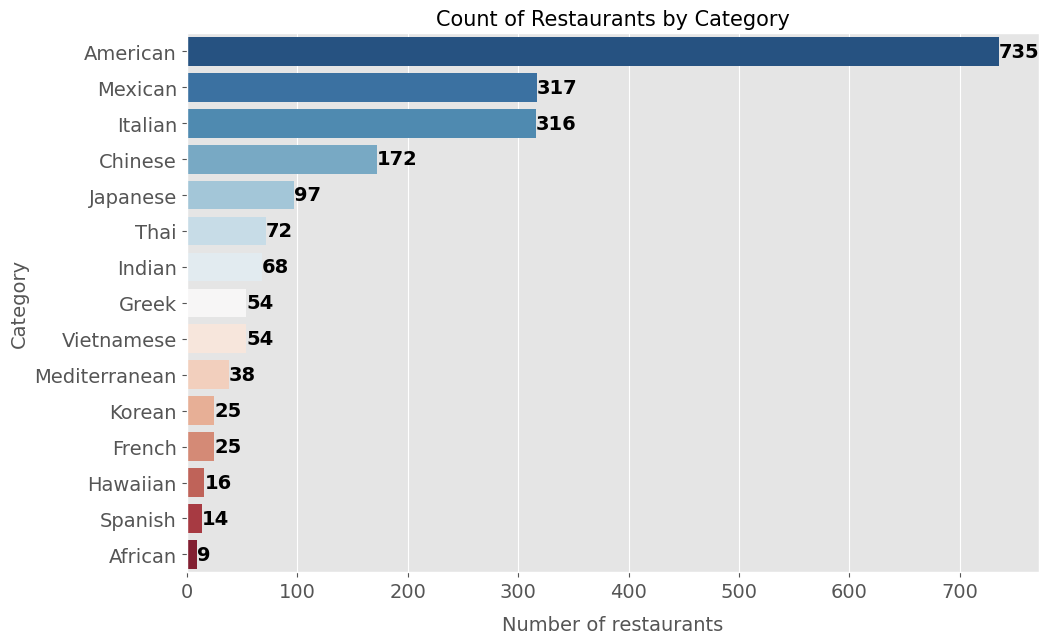

In [35]:
plt.figure(figsize=(11,7))
grouped = us_restaurants.category.value_counts()
sns.countplot(y='category',data=us_restaurants,
              order = grouped.index, palette= sns.color_palette("RdBu_r", len(grouped)))
plt.xlabel('Number of restaurants', fontsize=14, labelpad=10)
plt.ylabel('Category', fontsize=14)
plt.title('Count of Restaurants by Category', fontsize=15)
plt.tick_params(labelsize=14)
for  i, v in enumerate(us_restaurants.category.value_counts()):
    plt.text(v, i+0.15, str(v), fontweight='bold', fontsize=14)

Categories in dark blue color have the largest number of restaurants. On the contrary, categories in dark red color have the least number of restaurants. The top 5 type of restaurants are American, Mexican, Italian, Chinese and Japanese.

#### Top 10 cities with most restaurants

<ipython-input-36-765dc9348616>:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='City', y='Number of restaurants', data=grouped_df, palette=sns.color_palette("GnBu_r", len(grouped_df)))


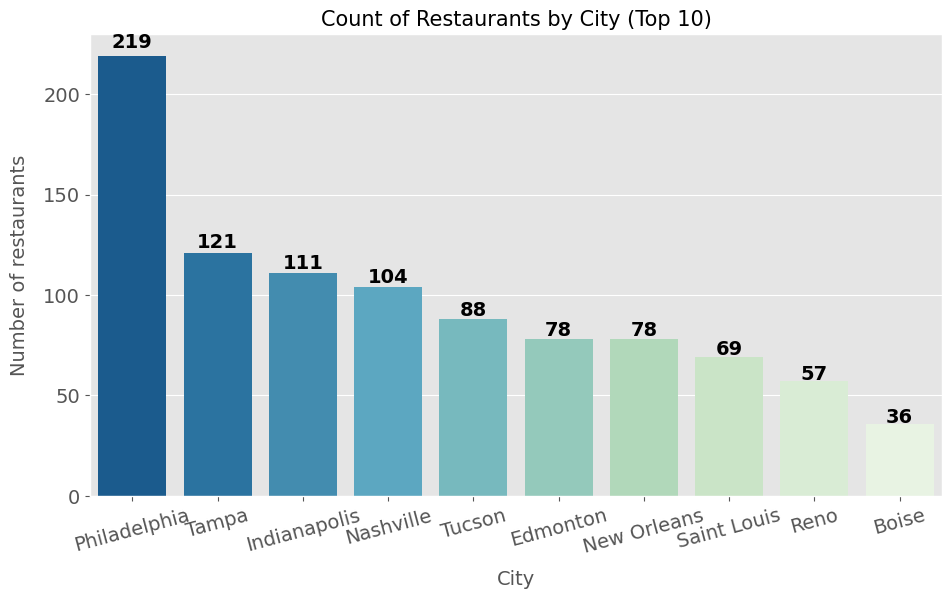

In [36]:
plt.figure(figsize=(11,6))
grouped = us_restaurants.city.value_counts()[:10]

# Convert the Series to a DataFrame for plotting with seaborn's newer API
grouped_df = grouped.reset_index()
grouped_df.columns = ['City', 'Number of restaurants']

sns.barplot(x='City', y='Number of restaurants', data=grouped_df, palette=sns.color_palette("GnBu_r", len(grouped_df)))

plt.ylabel('Number of restaurants', fontsize=14, labelpad=10)
plt.xlabel('City', fontsize=14, labelpad=10)
plt.title('Count of Restaurants by City (Top 10)', fontsize=15)
plt.tick_params(labelsize=14)
plt.xticks(rotation=15)

# The text annotation loop needs to be adjusted to use the DataFrame
for  i, v in enumerate(grouped_df['Number of restaurants']):
    plt.text(i, v*1.02, str(v), horizontalalignment ='center',fontweight='bold', fontsize=14)

#### Distribution of restaurants in each state

<ipython-input-37-3f64a98eaac2>:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='State', y='Number of restaurants', data=grouped_df, palette=sns.color_palette("GnBu_r", len(grouped_df)))


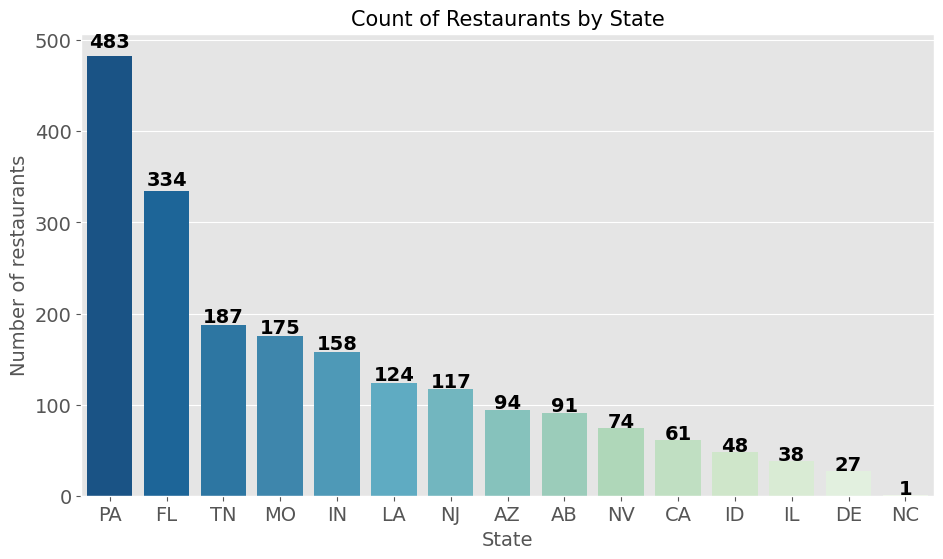

In [37]:
plt.figure(figsize=(11,6))
grouped = us_restaurants.state.value_counts()

# Convert the Series to a DataFrame for plotting with seaborn
grouped_df = grouped.reset_index()
grouped_df.columns = ['State', 'Number of restaurants']

sns.barplot(x='State', y='Number of restaurants', data=grouped_df, palette=sns.color_palette("GnBu_r", len(grouped_df)))

plt.ylabel('Number of restaurants', fontsize=14)
plt.xlabel('State', fontsize=14)
plt.title('Count of Restaurants by State', fontsize=15)
plt.tick_params(labelsize=14)
# Adjust the text annotation loop to use the DataFrame
for  i, v in enumerate(grouped_df['Number of restaurants']):
    plt.text(i, v*1.02, str(v), horizontalalignment ='center', fontweight='bold', fontsize=14)

### Reviews Distribution

#### Distribution of reviews by cuisine type

<ipython-input-38-beb93abee5c5>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=grouped.index, x= grouped.values, palette= sns.color_palette("RdBu_r", len(grouped)) )


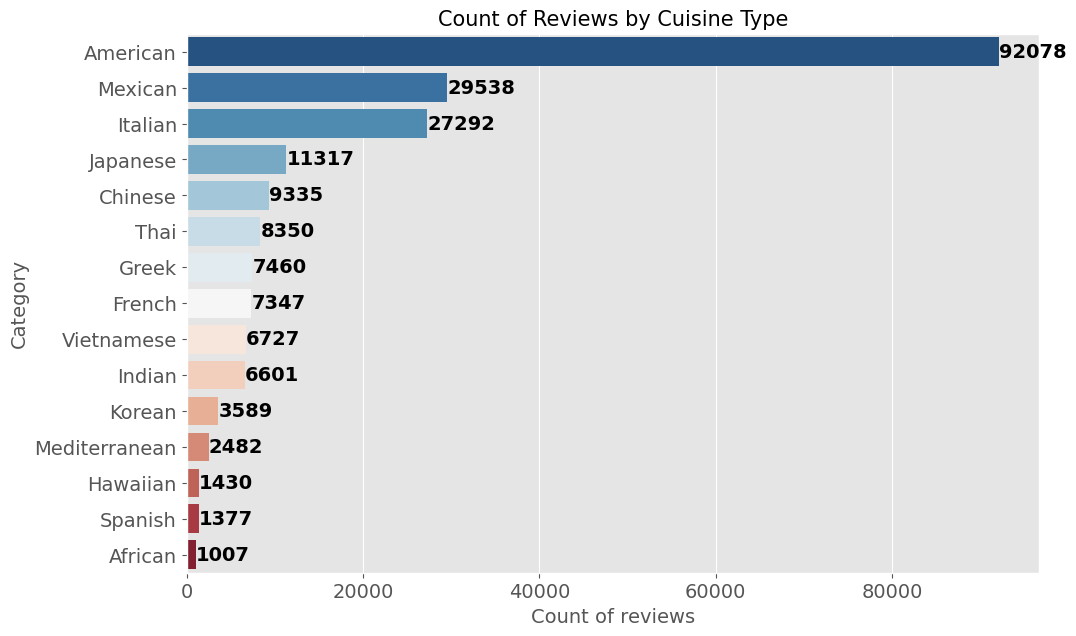

In [38]:
plt.figure(figsize=(11,7))
grouped = us_restaurants.groupby('category')['review_count'].sum().sort_values(ascending = False)
sns.barplot(y=grouped.index, x= grouped.values, palette= sns.color_palette("RdBu_r", len(grouped)) )
plt.ylabel('Category', fontsize=14)
plt.xlabel('Count of reviews', fontsize=14)
plt.title('Count of Reviews by Cuisine Type', fontsize=15)
for i,v in enumerate(grouped):
    plt.text(v, i+0.15, str(v),fontweight='bold', fontsize=14)
plt.tick_params(labelsize=14)

#### Top 10 cities with most reviews

<ipython-input-39-02b4c68c9508>:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=grouped.index, y=grouped.values, palette=sns.color_palette("GnBu_r", len(grouped)))


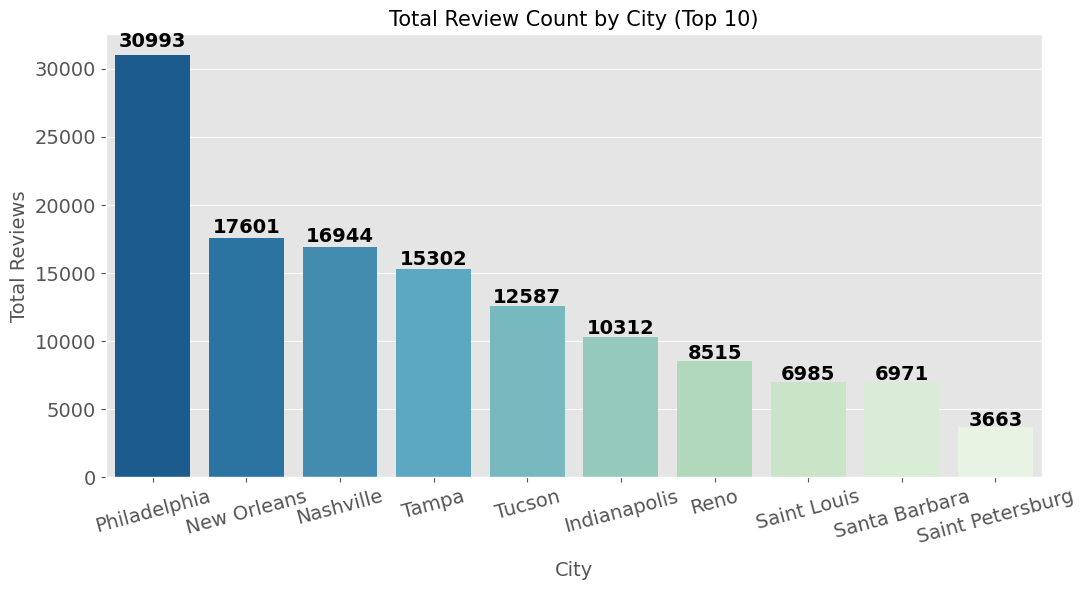

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(11, 6))

# Top 10 cities by total reviews
grouped = us_restaurants.groupby('city')['review_count'].sum().sort_values(ascending=False).head(10)

#  barplot call
sns.barplot(x=grouped.index, y=grouped.values, palette=sns.color_palette("GnBu_r", len(grouped)))

plt.xlabel('City', labelpad=10, fontsize=14)
plt.ylabel('Total Reviews', fontsize=14)
plt.title('Total Review Count by City (Top 10)', fontsize=15)
plt.tick_params(labelsize=14)
plt.xticks(rotation=15)

# Annotate bars
for i, v in enumerate(grouped.values):
    plt.text(i, v * 1.02, str(v), ha='center', fontweight='bold', fontsize=14)

plt.tight_layout()
plt.show()


#### Top 9 restaurants with most reviews

<ipython-input-40-b532c57f1ad3>:3: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(x=grouped.review_count, y = grouped.name, palette=sns.color_palette("GnBu_r", len(grouped)), ci=None)
<ipython-input-40-b532c57f1ad3>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=grouped.review_count, y = grouped.name, palette=sns.color_palette("GnBu_r", len(grouped)), ci=None)


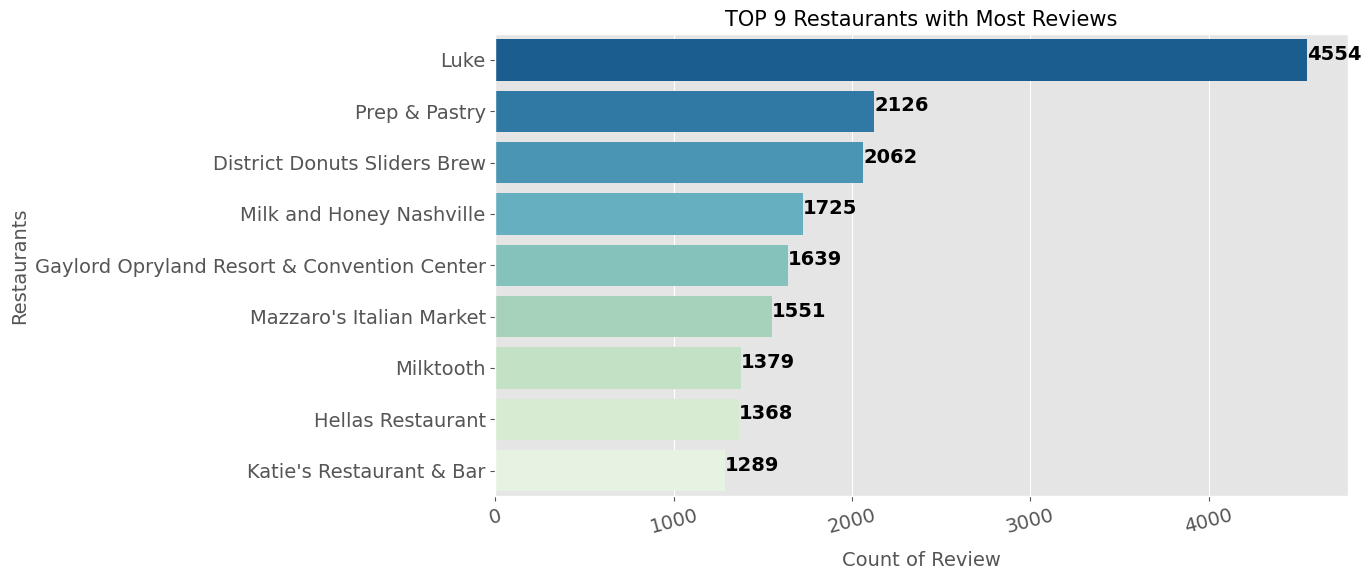

In [40]:
plt.figure(figsize=(11,6))
grouped = us_restaurants[['name','review_count']].sort_values(by='review_count', ascending=False)[:9]
sns.barplot(x=grouped.review_count, y = grouped.name, palette=sns.color_palette("GnBu_r", len(grouped)), ci=None)
plt.xlabel('Count of Review', labelpad=10, fontsize=14)
plt.ylabel('Restaurants', fontsize=14)
plt.title('TOP 9 Restaurants with Most Reviews', fontsize=15)
plt.tick_params(labelsize=14)
plt.xticks(rotation=15)
for  i, v in enumerate(grouped.review_count):
    plt.text(v, i, str(v), fontweight='bold', fontsize=14)

#### Distribution of positive and negative reviews in each category

In [41]:
table = pd.pivot_table(restaurants_reviews, values=["review_id"], index=["category"],columns=["labels"],
                       aggfunc=len, margins=True, dropna=True,fill_value=0)
table_percentage = table.div( table.iloc[:,-1], axis=0).iloc[:-1,-2].sort_values(ascending=False)

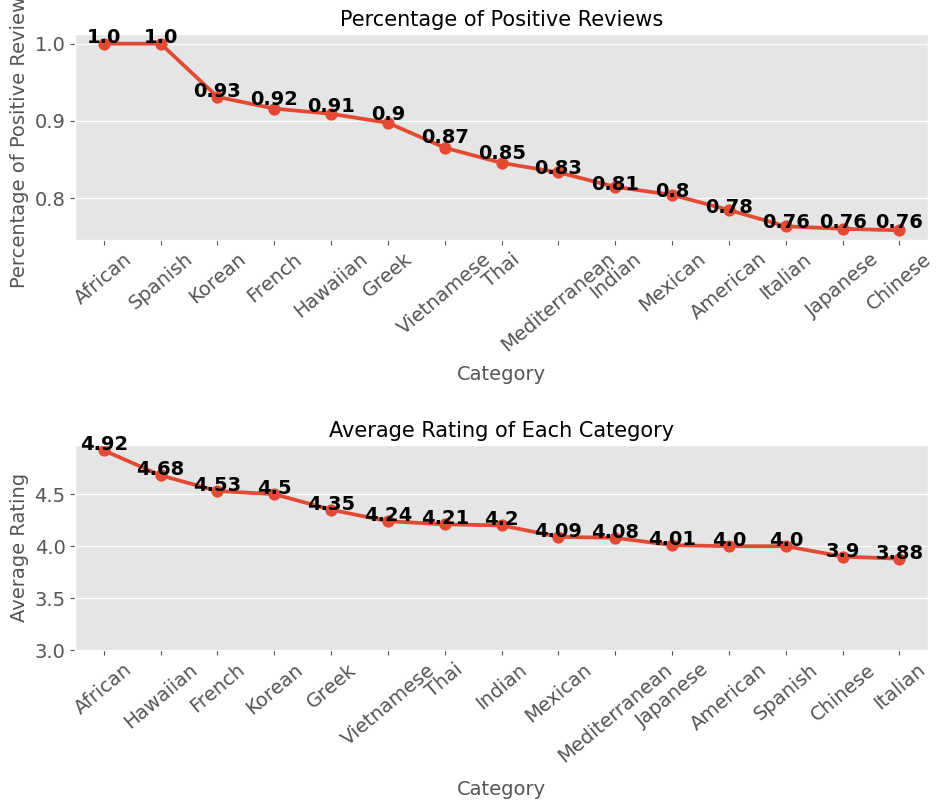

In [42]:
# Create pivot table of review counts by category and sentiment labels
table = pd.pivot_table(
    restaurants_reviews,
    values=["review_id"],
    index=["category"],
    columns=["labels"],
    aggfunc=len,
    margins=True,
    dropna=True,
    fill_value=0
)

# Compute % of positive reviews per category
table_percentage = table.div(table.iloc[:, -1], axis=0).iloc[:-1, -2].sort_values(ascending=False)

plt.figure(figsize=(11, 8))

# Plot 1: Percentage of Positive Reviews
plt.subplot(211)
sns.pointplot(x=table_percentage.index, y=table_percentage.values)
plt.xlabel('Category', labelpad=7, fontsize=14)
plt.ylabel('Percentage of Positive Reviews', fontsize=14)
plt.title('Percentage of Positive Reviews', fontsize=15)
plt.tick_params(labelsize=14)
plt.xticks(rotation=40)

for i, v in enumerate(table_percentage.round(2)):
    plt.text(i, v * 1.001, str(v), ha='center', fontweight='bold', fontsize=14)

# Plot 2: Average Rating per Category
plt.subplot(212)
grouped = restaurants_reviews.groupby('category')['review_star'].mean().round(2).sort_values(ascending=False)
sns.pointplot(x=grouped.index, y=grouped.values)  # ✅ FIXED HERE

plt.ylim(3)
plt.xlabel('Category', labelpad=10, fontsize=14)
plt.ylabel('Average Rating', fontsize=14)
plt.title('Average Rating of Each Category', fontsize=15)
plt.tick_params(labelsize=14)
plt.xticks(rotation=40)

for i, v in enumerate(grouped):
    plt.text(i, v, str(v), ha='center', fontweight='bold', fontsize=14)

plt.subplots_adjust(hspace=1)
plt.show()


#### Average length of reviews

#### Average length of words in each category

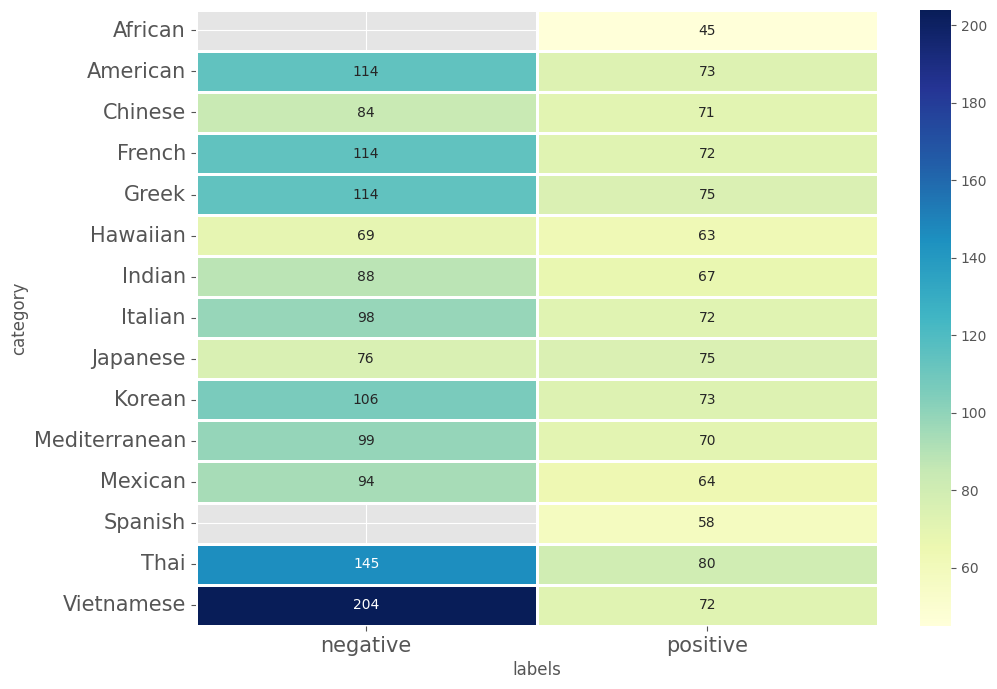

In [43]:
table = restaurants_reviews.groupby(['category','labels'])['num_words_review'].mean().round().unstack()
plt.figure(figsize=(11,8))
sns.heatmap(table, cmap='YlGnBu', fmt='g',annot=True, linewidths=1)
plt.tick_params(labelsize=15)

### Ratings Distribution

#### Distribution of ratings by restaurants

<ipython-input-44-c8f56b468c8d>:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=grouped.index, y=grouped.values, palette=sns.color_palette("RdBu_r", len(grouped)))


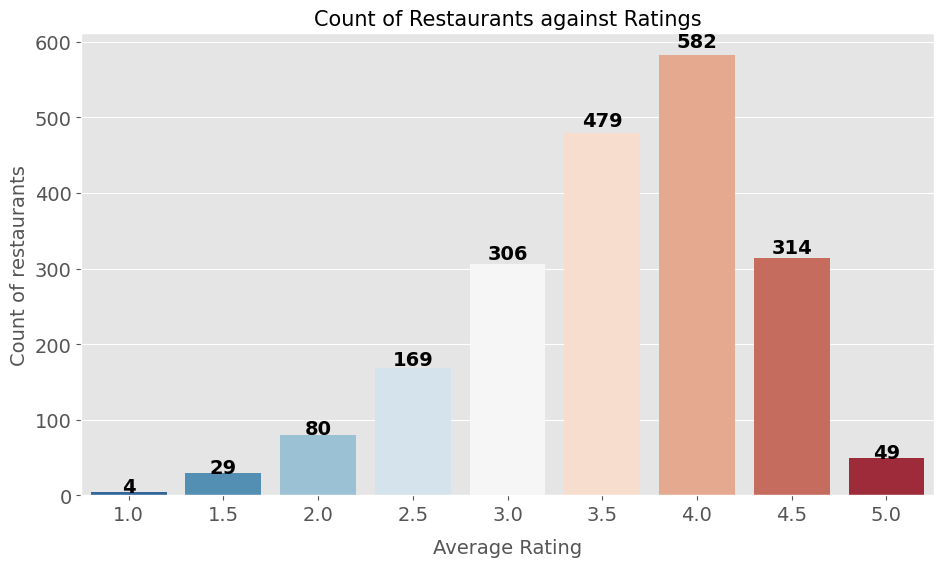

In [44]:
plt.figure(figsize=(11,6))
grouped = us_restaurants.stars.value_counts().sort_index()
# Pass the index to x and values to y using keyword arguments
sns.barplot(x=grouped.index, y=grouped.values, palette=sns.color_palette("RdBu_r", len(grouped)))
plt.xlabel('Average Rating', labelpad=10, fontsize=14)
plt.ylabel('Count of restaurants', fontsize=14)
plt.title('Count of Restaurants against Ratings', fontsize=15)
plt.tick_params(labelsize=14)
for  i, v in enumerate(grouped):
    plt.text(i, v*1.02, str(v), horizontalalignment ='center',fontweight='bold', fontsize=14)

#### Distribution of ratings by reviews

<ipython-input-45-35414acd3904>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=grouped.index, y=grouped.values, palette=sns.color_palette("RdBu_r", len(grouped)))


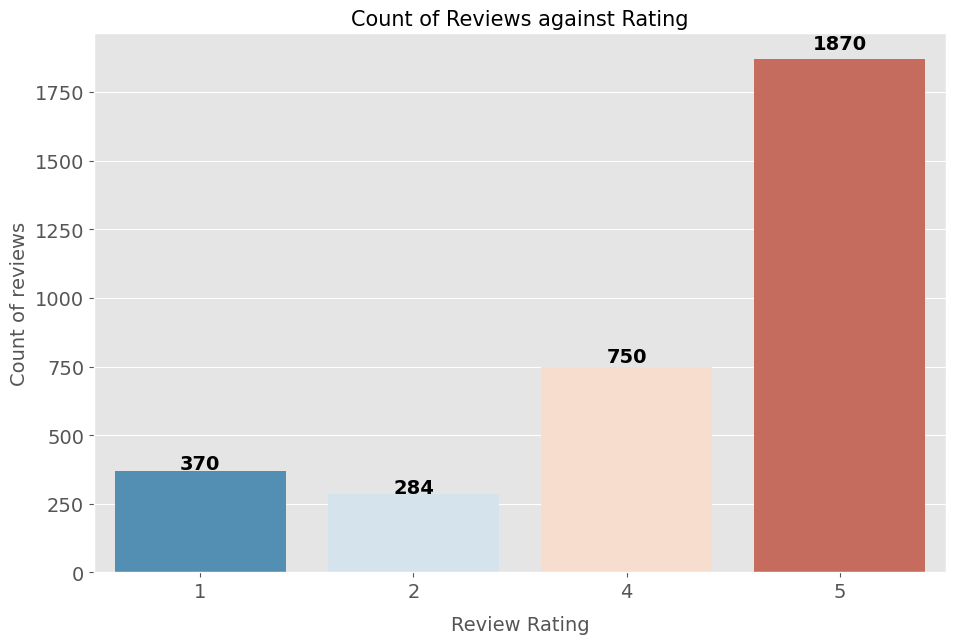

In [45]:
plt.figure(figsize=(11,7))
grouped = restaurants_reviews.review_star.value_counts().sort_index()
sns.barplot(x=grouped.index, y=grouped.values, palette=sns.color_palette("RdBu_r", len(grouped)))
plt.xlabel('Review Rating', labelpad=10, fontsize=14)
plt.ylabel('Count of reviews', fontsize=14)
plt.title('Count of Reviews against Rating', fontsize=15)
plt.tick_params(labelsize=14)
for  i, v in enumerate(grouped):
    plt.text(i, v*1.02, str(v), horizontalalignment ='center',fontweight='bold', fontsize=14)

## Review Analysis

### Positive words and negative words

In [46]:
import csv
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.svm import LinearSVC
pd.set_option('display.float_format', lambda x: '%.4f' % x)

## convert text to lower case
restaurants_reviews.text = restaurants_reviews.text.str.lower()

## remove unnecessary punctuation
restaurants_reviews['removed_punct_text']= restaurants_reviews.text.str.replace('\n',''). \
                                          str.replace('[!"#$%&\()*+,-./:;<=>?@[\\]^_`{|}~]','')

## import positive file which contains common meaningless positive words such as good
# Specify the encoding when opening the file
with open('/content/positive.txt', encoding='latin-1') as file_positive:
    reader = csv.reader(file_positive)
    positive_words = [word[0] for word in reader]

## import negative file which contains common meaningless positive words such as bad
# Specify the encoding when opening the file
with open('/content/negative.txt', encoding='latin-1') as file_negative:
    reader = csv.reader(file_negative)
    negative_words = [word[0] for word in reader]

In [47]:
## get dataset by category
def get_dataset(category):
    df = restaurants_reviews[['removed_punct_text','labels']][restaurants_reviews.category==category]
    df.reset_index(drop=True, inplace =True)
    df.rename(columns={'removed_punct_text':'text'}, inplace=True)
    return df



## only keep positive and negative words
def filter_words(review):
    words = [word for word in review.split() if word in positive_words + negative_words]
    words = ' '.join(words)
    return words

### Use Indian as an example

In [50]:
Indian_reviews = get_dataset('Indian')

In [51]:
Indian_train, Korean_test = train_test_split(Indian_reviews[['text','labels']],test_size=0.5)

In [53]:
print('Total %d number of reviews' % Indian_train.shape[0])

Total 48 number of reviews


In [54]:
def split_data(dataset, test_size):
    df_train, df_test = train_test_split(dataset[['text','labels']],test_size=test_size)
    return df_train

In [58]:
## filter words
Indian_train.text = Indian_train.text.apply(filter_words)
Indian_test.text = Indian_train.text.apply(filter_words)

In [59]:
Indian_train, Indian_test = train_test_split(Indian_reviews[['text','labels']],test_size=0.5)

In [60]:
## construct features and labels
terms_train=list(Indian_train['text'])
class_train=list(Indian_train['labels'])

terms_test=list(Indian_test['text'])
class_test=list(Indian_test['labels'])

In [61]:
## get bag of words : the frequencies of various words appeared in each review
vectorizer = CountVectorizer()
feature_train_counts=vectorizer.fit_transform(terms_train)
feature_train_counts.shape

(48, 857)

In [62]:
## run model
svm = LinearSVC()
svm.fit(feature_train_counts, class_train)

LinearSVC()

Support Vector Machine (SVM) model was applied to differentiate positive and
negative words in reviews, and further to get a word score to understand how positive or how negative the words are.

### Now we can calculate polarity score of each word in the specific category

#### Indian

In [65]:
## create dataframe for score of each word in a review calculated by svm model
coeff = svm.coef_[0]
# Replace get_feature_names() with get_feature_names_out()
Indian_words_score = pd.DataFrame({'score': coeff, 'word': vectorizer.get_feature_names_out()})

In [68]:
## get frequency of each word in all reviews in specific category
Indian_reviews = pd.DataFrame(feature_train_counts.toarray(), columns=vectorizer.get_feature_names_out())
Indian_reviews['labels'] = class_train
Indian_frequency = Indian_reviews[Indian_reviews['labels'] =='positive'].sum()[:-1]

In [70]:
Indian_words_score.set_index('word', inplace=True)

In [72]:
Indian_polarity_score = Indian_words_score
Indian_polarity_score['frequency'] = Indian_frequency

‘polarity score’ (a value that reflects the polarity of
sentiment) towards each restaurant category, the sentiment
score of each word was first multiplied by its frequency, and
then normalized by the total number of reviews for the specific
category of restaurants.

𝑝𝑜𝑙𝑎𝑟𝑖𝑡𝑦_𝑠𝑐𝑜𝑟𝑒 𝑡, 𝑐 = 𝑠𝑐𝑜𝑟𝑒(𝑡)×
𝑡𝑜𝑡𝑎𝑙_𝑓𝑟𝑒𝑞𝑢𝑒𝑛𝑐𝑦(𝑡, 𝑐)
𝑛𝑢𝑚𝑏𝑒𝑟_𝑜𝑓_ 𝑟𝑒𝑣𝑖𝑒𝑤𝑠(𝑐)

𝑝𝑜𝑙𝑎𝑟𝑖𝑡𝑦_𝑠𝑐𝑜𝑟𝑒 𝑡, 𝑐 is the index for measuring how
essential word 𝑡 is among restaurants of type 𝑐

𝑡𝑜𝑡𝑎𝑙_𝑓𝑟𝑒𝑞𝑢𝑒𝑛𝑐𝑦(𝑡, 𝑐) is the total frequency of word 𝑡 in
all reviews of type 𝑐 restaurants

𝑛𝑢𝑚𝑏𝑒𝑟_𝑜𝑓_ 𝑟𝑒𝑣𝑖𝑒𝑤𝑠(𝑐) is the total number of reviews of
type 𝑐 restaurants.

In [74]:
## calculate polarity score
Indian_polarity_score['polarity'] = Indian_polarity_score.score * Indian_polarity_score.frequency / Indian_reviews.shape[0]

since the SVM model actually calculate a total
score for each review, and this score to some extent indicates
how satisfied or discontented the customer is. The polarity
score we calculated shows how much a word contributes to the
score of all restaurants of a certain type. For example, the score
of French restaurants is lowered by 0.15 in average due to
‘overpriced’ while is lowered by only 0.02 due to ‘dirty’. Then
we might claim that ‘overpriced’ displeased customers a lot
more than ‘dirty’, and thus ‘overpriced’ is a more essential
(negative) characteristic of French restaurants.
Then for each category of restaurants, the top positive and
negative words are extracted. We may discover what are the
special features for each type and the discrepancy of those
restaurants providing great food around the world.

In order to find specific words that were used to indicate
customers’ concerns for the restaurant, or by moving forward
exploring the unique characteristic of each restaurant category,
adjectives that simply describing the polarity of sentiment (i.e.
“good”, “amazing”, “terrible” and etc.) were neglected.

In [85]:
# List of words to drop
positive_words_to_drop = [
    'great', 'amazing', 'love', 'best', 'awesome', 'excellent', 'good', 'favorite', 'loved',
    'perfect', 'gem', 'perfectly', 'wonderful', 'happy', 'enjoyed', 'nice', 'well', 'super',
    'like', 'better', 'decent', 'fine', 'pretty', 'enough', 'excited', 'impressed', 'ready',
    'fantastic', 'glad', 'right', 'fabulous'
]

negative_words_to_drop = [
    'bad', 'disappointed', 'unfortunately', 'disappointing', 'horrible',
    'lacking', 'terrible', 'sorry', 'disappoint'
]

# Drop only existing words to avoid KeyError
Indian_polarity_score.drop(
    index=Indian_polarity_score.index.intersection(positive_words_to_drop),
    inplace=True
)

Indian_polarity_score.drop(
    index=Indian_polarity_score.index.intersection(negative_words_to_drop),
    inplace=True
)


In [86]:
Indian_polarity_score.polarity =  Indian_polarity_score.polarity.astype(float)
Indian_polarity_score.frequency = Indian_polarity_score.frequency.astype(float)

In [88]:
Indian_polarity_score[Indian_polarity_score.polarity>0].sort_values('polarity', ascending=False)[:20]

,score,frequency,polarity
word,,,
the,0.0792,146.0000,0.2410
was,0.0825,53.0000,0.0911
indian,0.1293,24.0000,0.0647
of,0.0567,43.0000,0.0508
service,0.1277,19.0000,0.0505
and,0.0255,82.0000,0.0435
here,0.1226,16.0000,0.0409
definitely,0.1237,12.0000,0.0309
you,0.0713,18.0000,0.0267


#### Get top 10 most informative positive and negative words

In [90]:
# Define top sentiment words
Indian_top_positive_words = ['delicious','friendly','attentive','recommend','fresh','variety','reasonable','tender','clean','authentic']
Indian_top_negative_words = ['bland','slow','expensive','overpriced', 'cold', 'greasy','sweet','fatty','rude','dirty']

# Merge both lists
all_top_words = Indian_top_positive_words + Indian_top_negative_words

# Ensure only valid words are used
valid_words = Indian_polarity_score.index.intersection(all_top_words)

# Safely extract polarity values
Indian_top_words = Indian_polarity_score.loc[valid_words, 'polarity']


<ipython-input-91-c340b35c8d66>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=Indian_top_words.index, x=Indian_top_words.values, palette=colors)


(array([0.   , 0.002, 0.004, 0.006, 0.008, 0.01 ]),
 [Text(0.0, 0, '0.000'),
  Text(0.002, 0, '0.002'),
  Text(0.004, 0, '0.004'),
  Text(0.006, 0, '0.006'),
  Text(0.008, 0, '0.008'),
  Text(0.01, 0, '0.010')])

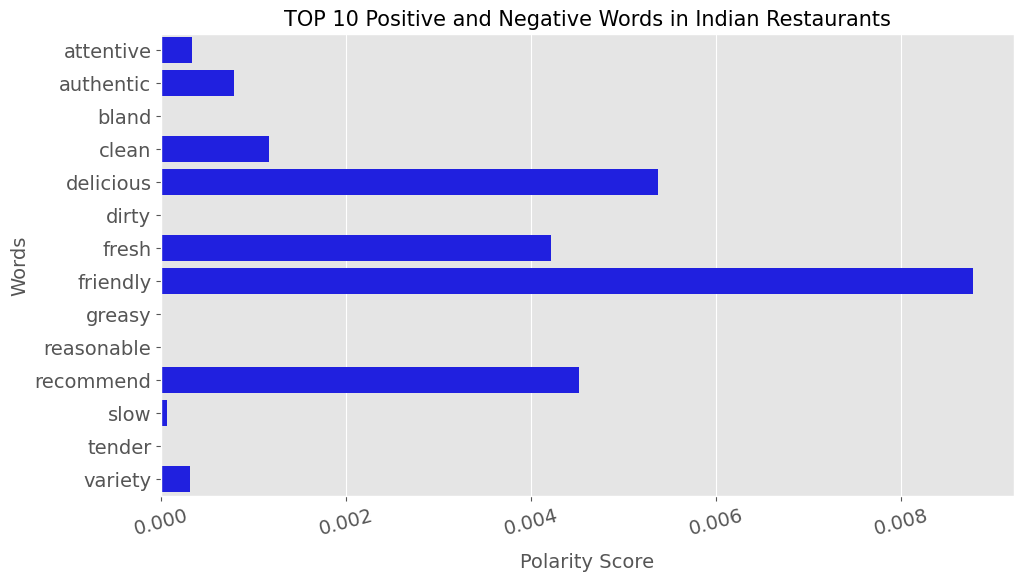

In [91]:
plt.figure(figsize=(11,6))
colors = ['red' if c < 0 else 'blue' for c in Indian_top_words.values]
sns.barplot(y=Indian_top_words.index, x=Indian_top_words.values, palette=colors)
plt.xlabel('Polarity Score', labelpad=10, fontsize=14)
plt.ylabel('Words', fontsize=14)
plt.title('TOP 10 Positive and Negative Words in Indian Restaurants', fontsize=15)
plt.tick_params(labelsize=14)
plt.xticks(rotation=15)

In [92]:
def get_polarity_score(dataset):
    dataset.text = dataset.text.apply(filter_words)

    terms_train=list(dataset['text'])
    class_train=list(dataset['labels'])

    ## get bag of words
    vectorizer = CountVectorizer()
    feature_train_counts=vectorizer.fit_transform(terms_train)

    ## run model
    svm = LinearSVC()
    svm.fit(feature_train_counts, class_train)

    ## create dataframe for score of each word in a review calculated by svm model
    coeff = svm.coef_[0]
    cuisine_words_score = pd.DataFrame({'score': coeff, 'word': vectorizer.get_feature_names()})

    ## get frequency of each word in all reviews in specific category
    cuisine_reviews = pd.DataFrame(feature_train_counts.toarray(), columns=vectorizer.get_feature_names())
    cuisine_reviews['labels'] = class_train
    cuisine_frequency = cuisine_reviews[cuisine_reviews['labels'] =='positive'].sum()[:-1]

    cuisine_words_score.set_index('word', inplace=True)
    cuisine_polarity_score = cuisine_words_score
    cuisine_polarity_score['frequency'] = cuisine_frequency

    cuisine_polarity_score.score = cuisine_polarity_score.score.astype(float)
    cuisine_polarity_score.frequency = cuisine_polarity_score.frequency.astype(int)

    ## calculate polarity score
    cuisine_polarity_score['polarity'] = cuisine_polarity_score.score * cuisine_polarity_score.frequency / cuisine_reviews.shape[0]

    cuisine_polarity_score.polarity = cuisine_polarity_score.polarity.astype(float)
    ## drop unnecessary words
    unuseful_positive_words = ['great','amazing','love','best','awesome','excellent','good',
                                                   'favorite','loved','perfect','gem','perfectly','wonderful',
                                                    'happy','enjoyed','nice','well','super','like','better','decent','fine',
                                                    'pretty','enough','excited','impressed','ready','fantastic','glad','right',
                                                    'fabulous']
    unuseful_negative_words =  ['bad','disappointed','unfortunately','disappointing','horrible',
                                                    'lacking','terrible','sorry']
    unuseful_words = unuseful_positive_words + unuseful_negative_words
    cuisine_polarity_score.drop(cuisine_polarity_score.loc[unuseful_words].index, axis=0, inplace=True)

    return cuisine_polarity_score

In [93]:
def plot_top_words(top_words, category):
    plt.figure(figsize=(11,6))
    colors = ['red' if c < 0 else 'blue' for c in top_words.values]
    sns.barplot(y=top_words.index, x=top_words.values, palette=colors)
    plt.xlabel('Polarity Score', labelpad=10, fontsize=14)
    plt.ylabel('Words', fontsize=14)
    plt.title('TOP 10 Positive and Negative Words in %s Restaurants ' % category, fontsize=15)
    plt.tick_params(labelsize=14)
    plt.xticks(rotation=15)

In [94]:
def get_top_words(dataset, label, number=20):
    if label == 'positive':
        df = dataset[dataset.polarity>0].sort_values('polarity',ascending = False)[:number]
    else:
        df = dataset[dataset.polarity<0].sort_values('polarity')[:number]
    return df

#### Japanese

In [95]:
Japanese_reviews = get_dataset('Japanese')
Japanese_train = split_data(Japanese_reviews, 0.9)
print('Total %d number of reviews' % Japanese_train.shape[0])

Total 17 number of reviews


In [98]:
def get_polarity_score(dataset):
    dataset.text = dataset.text.apply(filter_words)

    terms_train=list(dataset['text'])
    class_train=list(dataset['labels'])

    ## get bag of words
    vectorizer = CountVectorizer()
    feature_train_counts=vectorizer.fit_transform(terms_train)

    ## run model
    svm = LinearSVC()
    svm.fit(feature_train_counts, class_train)

    ## create dataframe for score of each word in a review calculated by svm model
    coeff = svm.coef_[0]
    # Use get_feature_names_out() instead of get_feature_names()
    cuisine_words_score = pd.DataFrame({'score': coeff, 'word': vectorizer.get_feature_names_out()})

    ## get frequency of each word in all reviews in specific category
    cuisine_reviews = pd.DataFrame(feature_train_counts.toarray(), columns=vectorizer.get_feature_names_out())
    cuisine_reviews['labels'] = class_train
    cuisine_frequency = cuisine_reviews[cuisine_reviews['labels'] =='positive'].sum()[:-1]

    cuisine_words_score.set_index('word', inplace=True)
    cuisine_polarity_score = cuisine_words_score
    cuisine_polarity_score['frequency'] = cuisine_frequency

    cuisine_polarity_score.score = cuisine_polarity_score.score.astype(float)
    cuisine_polarity_score.frequency = cuisine_polarity_score.frequency.astype(int)

    ## calculate polarity score
    cuisine_polarity_score['polarity'] = cuisine_polarity_score.score * cuisine_polarity_score.frequency / cuisine_reviews.shape[0]

    cuisine_polarity_score.polarity = cuisine_polarity_score.polarity.astype(float)
    ## drop unnecessary words
    unuseful_positive_words = ['great','amazing','love','best','awesome','excellent','good',
                                                   'favorite','loved','perfect','gem','perfectly','wonderful',
                                                    'happy','enjoyed','nice','well','super','like','better','decent','fine',
                                                    'pretty','enough','excited','impressed','ready','fantastic','glad','right',
                                                    'fabulous']
    unuseful_negative_words =  ['bad','disappointed','unfortunately','disappointing','horrible',
                                                    'lacking','terrible','sorry']
    unuseful_words = unuseful_positive_words + unuseful_negative_words
    # Ensure that the index exists before attempting to drop
    words_to_drop = cuisine_polarity_score.index.intersection(unuseful_words)
    cuisine_polarity_score.drop(words_to_drop, axis=0, inplace=True)

    return cuisine_polarity_score

In [99]:
Japanese_polarity_score = get_polarity_score(Japanese_train)

In [100]:
get_top_words(Japanese_polarity_score, 'positive')

,score,frequency,polarity
word,,,
fresh,0.2895,3,0.0511
friendly,0.2098,3,0.0370
fried,0.1926,3,0.0340
exceptional,0.1850,2,0.0218
recommend,0.1710,2,0.0201
delicious,0.0925,2,0.0109
terrific,0.1817,1,0.0107
fast,0.1811,1,0.0107
slow,0.1472,1,0.0087


In [101]:
get_top_words(Japanese_polarity_score,'negative',20)

,score,frequency,polarity
word,,,
worth,-0.2864,2,-0.0337


In [103]:
# Define target sentiment word lists
Japanese_top_positive_words = ['delicious','friendly','fresh','recommend','fun','reasonable',
                               'creative','clean','variety','attentive']
Japanese_top_negative_words = ['hard','cold','wrong','slow','bland','dark','expensive',
                               'rude','overpriced','crowded']

# Merge both lists
all_top_words = Japanese_top_positive_words + Japanese_top_negative_words

# Use intersection to avoid KeyError
valid_words = Japanese_polarity_score.index.intersection(all_top_words)

# Filter only valid sentiment words
Japanese_top_words = Japanese_polarity_score.loc[valid_words, 'polarity']


<ipython-input-93-c037f11c90c5>:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=top_words.index, x=top_words.values, palette=colors)


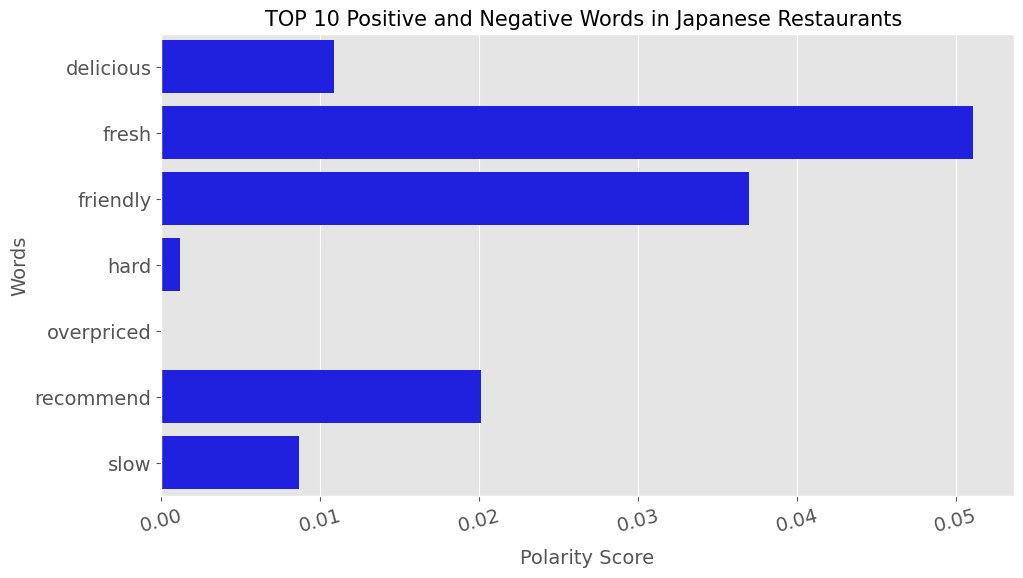

In [104]:
plot_top_words(Japanese_top_words,'Japanese')

#### Thai

In [105]:
Thai_reviews = get_dataset('Thai')
Thai_train = split_data(Thai_reviews, 0.8)
print('Total %d number of reviews' % Thai_train.shape[0])

Total 24 number of reviews


In [108]:
Thai_polarity_score = get_polarity_score(Thai_train)

In [109]:
get_top_words(Thai_polarity_score,'positive')

,score,frequency,polarity
word,,,
fresh,0.5407,5,0.1126
sweet,0.3224,2,0.0269
recommend,0.1534,4,0.0256
delicious,0.1533,3,0.0192
liked,0.3224,1,0.0134
reasonably,0.1534,2,0.0128
authentic,0.1248,2,0.0104
variety,0.2057,1,0.0086
dispute,0.2057,1,0.0086


In [110]:
get_top_words(Thai_polarity_score,'negative')

,score,frequency,polarity
word,,,
fried,-0.1240,5,-0.0258


<ipython-input-93-c037f11c90c5>:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=top_words.index, x=top_words.values, palette=colors)


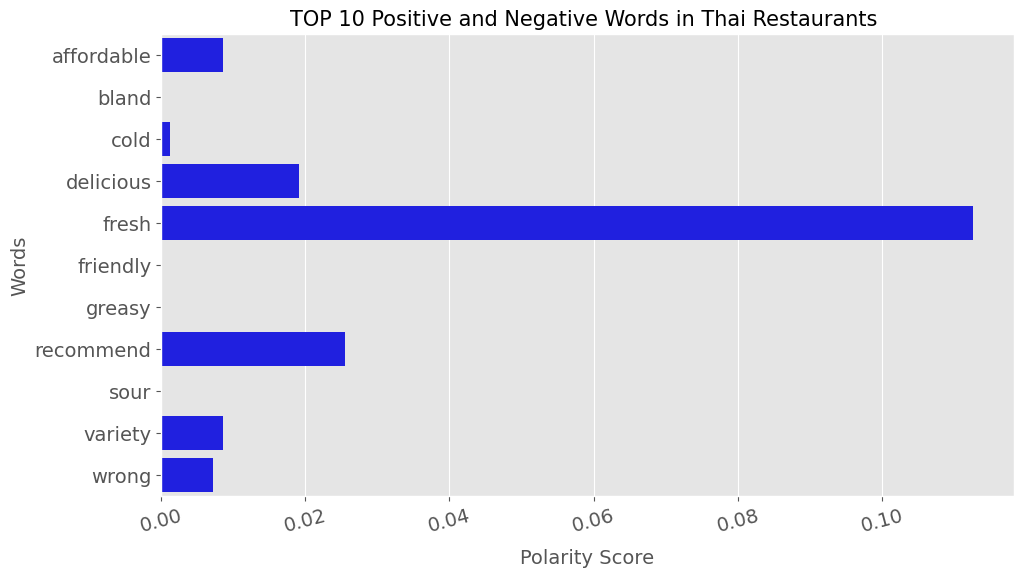

In [112]:
# Define top sentiment word lists
Thai_top_positive_words = ['delicious','friendly','fresh','recommend','reasonable',
                           'affordable','variety','attentive','fast','comfortable']
Thai_top_negative_words = ['bland','greasy','expensive','weird','wrong','slow',
                           'hard','cold','sour','mushy','mess']

# Merge all words
Thai_words_all = Thai_top_positive_words + Thai_top_negative_words

# Use only valid words that exist in the polarity score index
valid_thai_words = Thai_polarity_score.index.intersection(Thai_words_all)

# Extract polarity scores safely
Thai_top_words = Thai_polarity_score.loc[valid_thai_words, 'polarity']

# Plot results
plot_top_words(Thai_top_words, 'Thai')


#### Chinese

In [113]:
Chinese_reviews = get_dataset('Chinese')
Chinese_train = split_data(Chinese_reviews, 0.85)
print('Total %d number of reviews' % Chinese_train.shape[0])

Total 13 number of reviews


In [114]:
Chinese_polarity_score = get_polarity_score(Chinese_train)

In [115]:
get_top_words(Chinese_polarity_score,'positive')

,score,frequency,polarity
word,,,
fried,0.1641,3,0.0379
worth,0.0878,1,0.0068
mediocre,0.0878,1,0.0068
hot,0.0878,1,0.0068
delicious,0.0807,1,0.0062
fatty,0.0807,1,0.0062
authentic,0.0807,1,0.0062
clear,0.0807,1,0.0062
correct,0.0796,1,0.0061


In [116]:
get_top_words(Chinese_polarity_score,'negative')

,score,frequency,polarity
word,,,


<ipython-input-93-c037f11c90c5>:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=top_words.index, x=top_words.values, palette=colors)


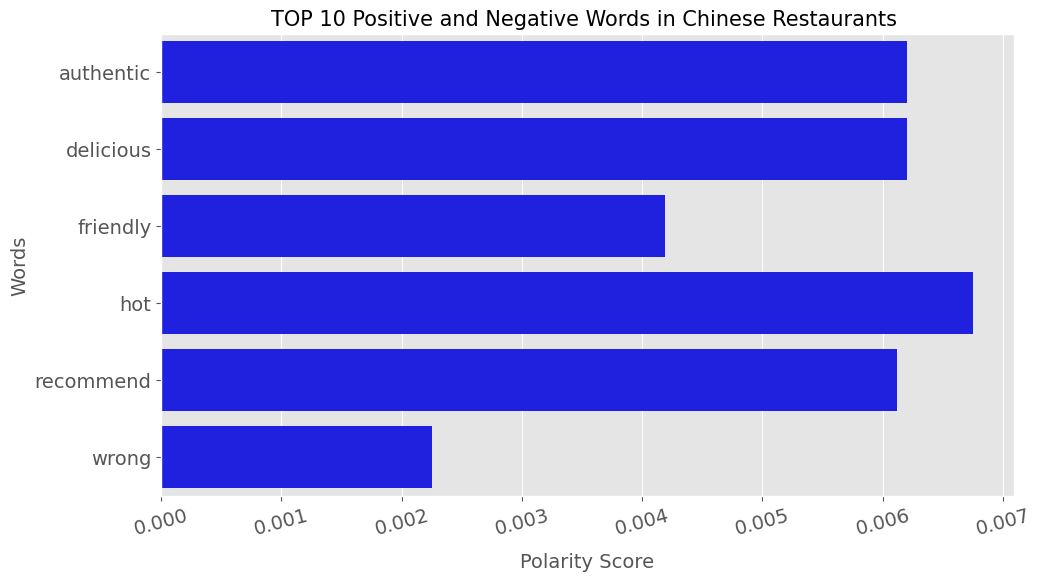

In [118]:
# Define word lists
Chinese_top_positive_words = ['delicious','friendly','fresh','authentic','reasonable','hot','fun',
                              'fast','tender','recommend']
Chinese_top_negative_words = ['sour','bland','cold','greasy','hard','slow','wrong','rude','overpriced','frozen']

# Combine all
Chinese_all_words = Chinese_top_positive_words + Chinese_top_negative_words

# Filter valid terms present in the polarity index
valid_chinese_words = Chinese_polarity_score.index.intersection(Chinese_all_words)

# Extract polarities safely
Chinese_top_words = Chinese_polarity_score.loc[valid_chinese_words, 'polarity']

# Plot safely
plot_top_words(Chinese_top_words, 'Chinese')


#### Vietnamese

In [119]:
Vietnamese_reviews = get_dataset('Vietnamese')
Vietnamese_train = split_data(Vietnamese_reviews, 0.7)
print('Total %d number of reviews' % Vietnamese_train.shape[0])

Total 26 number of reviews


In [120]:
Vietnamese_polarity_score = get_polarity_score(Vietnamese_train)

In [121]:
get_top_words(Vietnamese_polarity_score,'positive')

,score,frequency,polarity
word,,,
authentic,0.3449,4,0.0531
friendly,0.2080,3,0.0240
warm,0.3013,2,0.0232
die,0.5458,1,0.0210
recommend,0.1883,2,0.0145
delicious,0.0496,4,0.0076
fresh,0.0488,4,0.0075
reasonably,0.1817,1,0.0070
accurate,0.1592,1,0.0061


In [122]:
get_top_words(Vietnamese_polarity_score,'negative')

,score,frequency,polarity
word,,,
hot,-0.1360,1,-0.0052


<ipython-input-93-c037f11c90c5>:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=top_words.index, x=top_words.values, palette=colors)


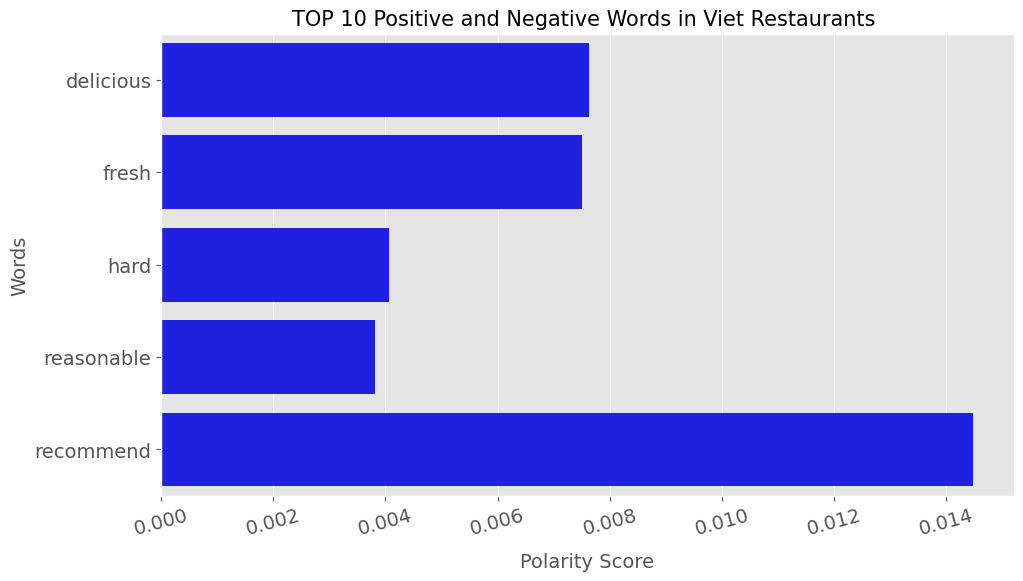

In [124]:
# Define top words
Viet_top_positive_words = ['delicious','fresh','clean','fast','recommend','reasonable','tender',
                           'fancy','refreshing','generous']
Viet_top_negative_words = ['bland','wrong','hard','slow','expensive','rude','greasy','dirty','weird','smelled']

# Combine all words
Viet_all_words = Viet_top_positive_words + Viet_top_negative_words

# Ensure only valid words are used
valid_viet_words = Vietnamese_polarity_score.index.intersection(Viet_all_words)

# Extract polarities safely
Viet_top_words = Vietnamese_polarity_score.loc[valid_viet_words, 'polarity']

# Plot
plot_top_words(Viet_top_words, 'Viet')


#### French

In [125]:
French_reviews = get_dataset('French')
French_train = split_data(French_reviews, 0.7)
print('Total %d number of reviews' % French_train.shape[0])

Total 32 number of reviews


Total 85 number of reviews


<ipython-input-93-c037f11c90c5>:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=top_words.index, x=top_words.values, palette=colors)


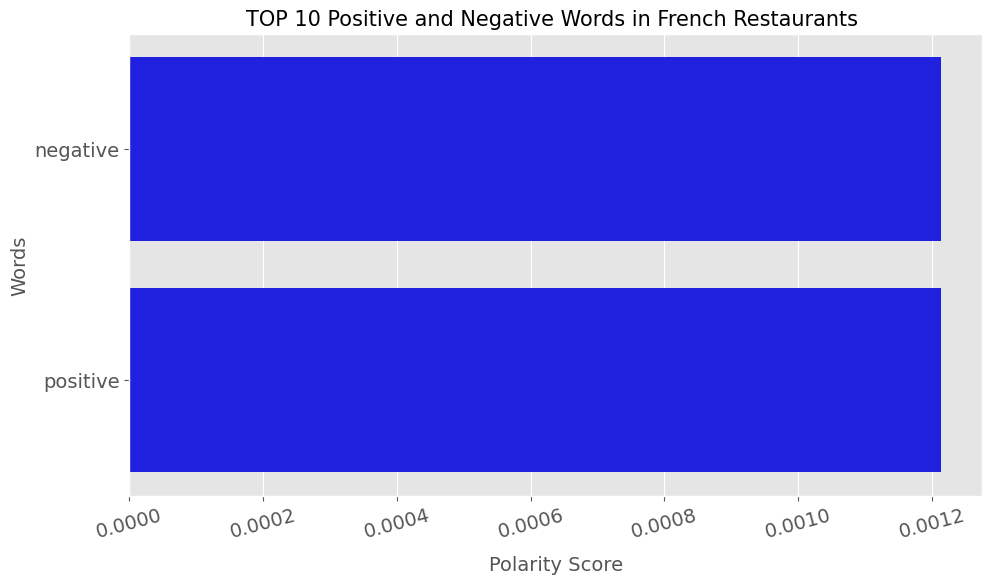

In [129]:
def get_polarity_score(dataset):
    dataset.text = dataset.text.apply(filter_words)

    terms_train=list(dataset['text'])
    class_train=list(dataset['labels'])

    ## get bag of words
    vectorizer = CountVectorizer()
    feature_train_counts=vectorizer.fit_transform(terms_train)

    ## run model
    svm = LinearSVC()
    # Add a check to ensure there are at least two classes before fitting
    if len(set(class_train)) < 2:
        print(f"Skipping polarity score calculation: Training data contains only one class ({set(class_train).pop()})")
        return None # Or handle as appropriate
    else:
        svm.fit(feature_train_counts, class_train)

    ## create dataframe for score of each word in a review calculated by svm model
    coeff = svm.coef_[0]
    # Use get_feature_names_out() instead of get_feature_names()
    cuisine_words_score = pd.DataFrame({'score': coeff, 'word': vectorizer.get_feature_names_out()})

    ## get frequency of each word in all reviews in specific category
    cuisine_reviews = pd.DataFrame(feature_train_counts.toarray(), columns=vectorizer.get_feature_names_out())
    cuisine_reviews['labels'] = class_train
    cuisine_frequency = cuisine_reviews[cuisine_reviews['labels'] =='positive'].sum()[:-1]

    cuisine_words_score.set_index('word', inplace=True)
    cuisine_polarity_score = cuisine_words_score
    cuisine_polarity_score['frequency'] = cuisine_frequency

    cuisine_polarity_score.score = cuisine_polarity_score.score.astype(float)
    # Handle potential KeyError if 'positive' frequency is empty
    if not cuisine_frequency.empty:
        cuisine_polarity_score.frequency = cuisine_polarity_score.frequency.astype(int)
    else:
        cuisine_polarity_score.frequency = 0 # Or handle as appropriate

    ## calculate polarity score
    # Avoid division by zero if cuisine_reviews.shape[0] is 0, though likely not the case here
    if cuisine_reviews.shape[0] > 0:
        cuisine_polarity_score['polarity'] = cuisine_polarity_score.score * cuisine_polarity_score.frequency / cuisine_reviews.shape[0]
    else:
        cuisine_polarity_score['polarity'] = 0

    cuisine_polarity_score.polarity = cuisine_polarity_score.polarity.astype(float)
    ## drop unnecessary words
    unuseful_positive_words = ['great','amazing','love','best','awesome','excellent','good',
                                                   'favorite','loved','perfect','gem','perfectly','wonderful',
                                                    'happy','enjoyed','nice','well','super','like','better','decent','fine',
                                                    'pretty','enough','excited','impressed','ready','fantastic','glad','right',
                                                    'fabulous']
    unuseful_negative_words =  ['bad','disappointed','unfortunately','disappointing','horrible',
                                                    'lacking','terrible','sorry']
    unuseful_words = unuseful_positive_words + unuseful_negative_words
    # Ensure that the index exists before attempting to drop
    words_to_drop = cuisine_polarity_score.index.intersection(unuseful_words)
    cuisine_polarity_score.drop(words_to_drop, axis=0, inplace=True)

    return cuisine_polarity_score

# Change the split_data call for French reviews
French_reviews = get_dataset('French')
# Reduced test_size to increase the training set size
French_train = split_data(French_reviews, 0.2)
print('Total %d number of reviews' % French_train.shape[0])

# Now call the polarity score function
French_polarity_score = get_polarity_score(French_train)

# You might want to add a check here if French_polarity_score is None
if French_polarity_score is not None:
    # Continue with the analysis for French reviews
    get_top_words(French_polarity_score, 'positive')
    get_top_words(French_polarity_score, 'negative')
    # Define top words and plot as before
    French_top_positive_words = ['specific', 'positive', 'words'] # Replace with actual top words
    French_top_negative_words = ['specific', 'negative', 'words'] # Replace with actual top words
    French_all_words = French_top_positive_words + French_top_negative_words
    valid_french_words = French_polarity_score.index.intersection(French_all_words)
    French_top_words = French_polarity_score.loc[valid_french_words, 'polarity']
    plot_top_words(French_top_words, 'French')
else:
    print("Analysis for French reviews skipped due to insufficient data.")

In [130]:
French_polarity_score = get_polarity_score(French_train)

In [131]:
get_top_words(French_polarity_score,'positive')

,score,frequency,polarity
word,,,
rich,0.2789,7,0.0230
delicious,0.2442,6,0.0172
fresh,0.1071,11,0.0139
fancy,0.2488,3,0.0088
enjoy,0.2226,3,0.0079
top,0.0753,5,0.0044
split,0.1656,2,0.0039
miss,0.1084,3,0.0038
fried,0.0354,9,0.0037


In [132]:
get_top_words(French_polarity_score, 'negative')

,score,frequency,polarity
word,,,
recommend,-0.1425,11,-0.0184
worth,-0.1477,4,-0.0069
polite,-0.4659,1,-0.0055
thank,-0.0801,3,-0.0028
ideal,-0.0410,1,-0.0005


In [134]:
def safe_plot_top_words(polarity_df, word_list, cuisine_name):
    valid_words = [w for w in word_list if w in polarity_df.index]
    if not valid_words:
        print(f"⚠️ No matching words found in {cuisine_name}_polarity_score.")
        return
    top_words = polarity_df.loc[valid_words, 'polarity']
    plot_top_words(top_words, cuisine_name)


<ipython-input-93-c037f11c90c5>:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=top_words.index, x=top_words.values, palette=colors)


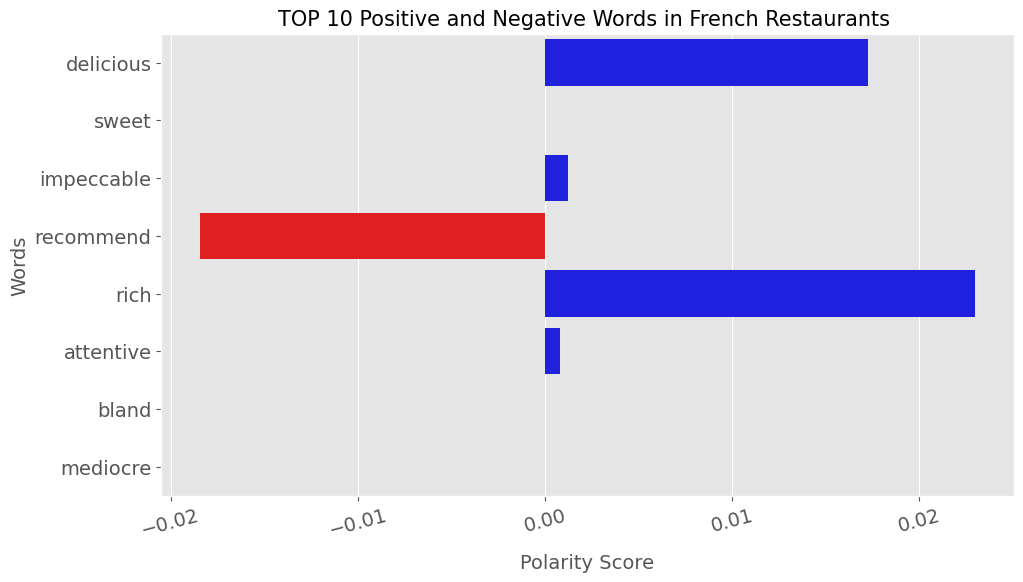

In [136]:
safe_plot_top_words(French_polarity_score, French_top_positive_words + French_top_negative_words, 'French')


#### Italian

In [138]:
Italian_reviews = get_dataset('Italian')
Italian_train = split_data(Italian_reviews, 0.9)
print('Total %d number of reviews' % Italian_train.shape[0])

Total 41 number of reviews


In [139]:
Italian_polarity_score = get_polarity_score(Italian_train)

In [140]:
get_top_words(Italian_polarity_score, 'positive',30)

,score,frequency,polarity
word,,,
hot,0.6572,2,0.0321
picky,0.5028,2,0.0245
recommend,0.2263,4,0.0221
favor,0.4160,2,0.0203
delicious,0.1477,5,0.0180
robust,0.7345,1,0.0179
fried,0.3017,2,0.0147
worth,0.1676,3,0.0123
work,0.2251,2,0.0110


In [141]:
get_top_words(Italian_polarity_score, 'negative',30)

,score,frequency,polarity
word,,,
friendly,-0.1489,5,-0.0182
helping,-0.6237,1,-0.0152
bother,-0.2131,1,-0.0052


In [144]:
Italian_top_positive_words = ['delicious', 'authentic', 'fresh', 'hot', 'tender', 'friendly',
                              'recommend', 'crispy', 'affordable', 'perfect']
Italian_top_negative_words = ['bland', 'cold', 'greasy', 'slow', 'wrong', 'overpriced',
                              'rude', 'disappointing', 'expensive', 'burnt']


In [145]:
def safe_plot_top_words(polarity_df, word_list, cuisine_name):
    valid_words = [w for w in word_list if w in polarity_df.index]
    if not valid_words:
        print(f"⚠️ No matching words found in {cuisine_name}_polarity_score.")
        return
    top_words = polarity_df.loc[valid_words, 'polarity']
    plot_top_words(top_words, cuisine_name)


<ipython-input-93-c037f11c90c5>:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=top_words.index, x=top_words.values, palette=colors)


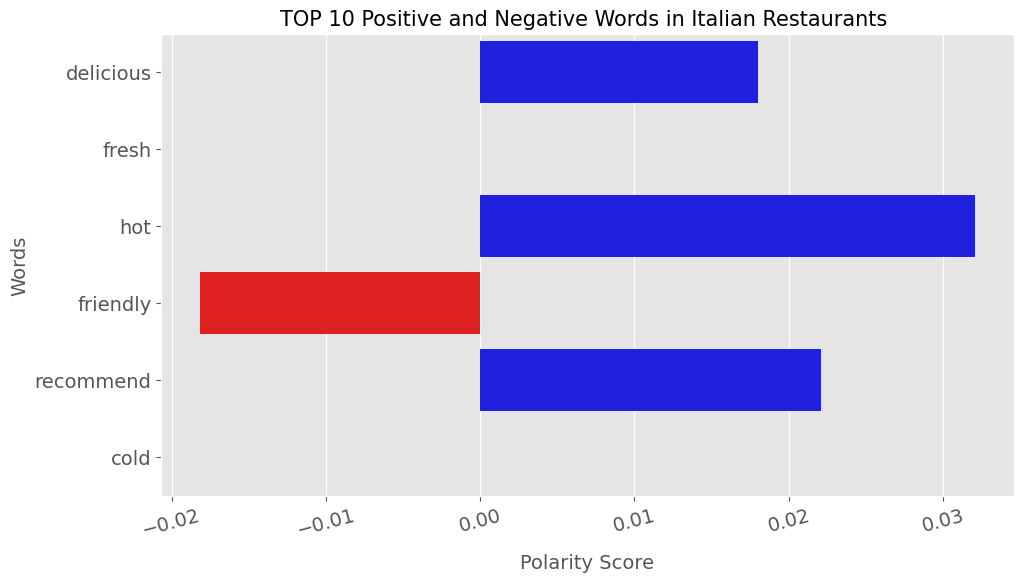

In [146]:
safe_plot_top_words(Italian_polarity_score, Italian_top_positive_words + Italian_top_negative_words, 'Italian')


### Combine all top words to compare among different cuisine typies

In [148]:
all_category = {'cuisine':['Korean','Japanese','Chinese','Thai','Vietnamese','French','Italian']}
cuisine_positive_words = pd.DataFrame(all_category)
for i,word in enumerate(Indian_top_positive_words):
    cuisine_positive_words.loc[0,i] = word

In [150]:
for i,word in enumerate(Indian_top_positive_words):
    cuisine_positive_words.iloc[0,i] = word
for i,word in enumerate(Japanese_top_positive_words):
    cuisine_positive_words.iloc[1,i] = word
for i,word in enumerate(Chinese_top_positive_words):
    cuisine_positive_words.iloc[2,i] = word
for i,word in enumerate(Thai_top_positive_words):
    cuisine_positive_words.iloc[3,i] = word
for i,word in enumerate(Viet_top_positive_words):
    cuisine_positive_words.iloc[4,i] = word
for i,word in enumerate(French_top_positive_words):
    cuisine_positive_words.iloc[5,i] = word
for i,word in enumerate(Italian_top_positive_words):
    cuisine_positive_words.iloc[6,i] = word

cuisine_positive_words.drop(9,axis=1,inplace=True)
cuisine_positive_words.columns=['0','1','2','3','4','5','6','7','8','9']
cuisine_positive_words['cuisine']=['Indian','Japanese','Chinese','Thai','Vietnamese','French','Italian']
cuisine_positive_words.set_index('cuisine', inplace=True)

In [152]:
all_category = {'cuisine':['Korean','Japanese','Chinese','Thai','Vietnamese','French','Italian']}
cuisine_negative_words = pd.DataFrame(all_category)
for i,word in enumerate(Indian_top_negative_words):
    cuisine_negative_words.loc[0,i] = word

In [153]:
for i,word in enumerate(Indian_top_negative_words):
    cuisine_negative_words.iloc[0,i] = word
for i,word in enumerate(Japanese_top_negative_words):
    cuisine_negative_words.iloc[1,i] = word
for i,word in enumerate(Chinese_top_negative_words):
    cuisine_negative_words.iloc[2,i] = word
for i,word in enumerate(Thai_top_negative_words):
    cuisine_negative_words.iloc[3,i] = word
for i,word in enumerate(Viet_top_negative_words):
    cuisine_negative_words.iloc[4,i] = word
for i,word in enumerate(French_top_negative_words):
    cuisine_negative_words.iloc[5,i] = word
for i,word in enumerate(Italian_top_negative_words):
    cuisine_negative_words.iloc[6,i] = word

cuisine_negative_words.drop(9,axis=1,inplace=True)
cuisine_negative_words.columns=['0','1','2','3','4','5','6','7','8','9']
cuisine_negative_words['cuisine']=['Korean','Japanese','Chinese','Thai','Vietnamese','French','Italian']
cuisine_negative_words.set_index('cuisine', inplace=True)

In [154]:
cuisine_positive_words

,0,1,2,3,4,5,6,7,8,9
cuisine,,,,,,,,,,
Indian,delicious,friendly,attentive,recommend,fresh,variety,reasonable,tender,clean,authentic
Japanese,delicious,friendly,fresh,recommend,fun,reasonable,creative,clean,variety,attentive
Chinese,delicious,friendly,fresh,authentic,reasonable,hot,fun,fast,tender,recommend
Thai,delicious,friendly,fresh,recommend,reasonable,affordable,variety,attentive,fast,comfortable
Vietnamese,delicious,fresh,clean,fast,recommend,reasonable,tender,fancy,refreshing,generous
French,delicious,sweet,tender,impeccable,recommend,rich,attentive,beautifully,crisp,romantic
Italian,delicious,authentic,fresh,hot,tender,friendly,recommend,crispy,affordable,perfect


In [155]:
cuisine_negative_words

,0,1,2,3,4,5,6,7,8,9
cuisine,,,,,,,,,,
Korean,bland,slow,expensive,overpriced,cold,greasy,sweet,fatty,rude,dirty
Japanese,hard,cold,wrong,slow,bland,dark,expensive,rude,overpriced,crowded
Chinese,sour,bland,cold,greasy,hard,slow,wrong,rude,overpriced,frozen
Thai,bland,greasy,expensive,weird,wrong,slow,hard,cold,sour,mushy
Vietnamese,bland,wrong,hard,slow,expensive,rude,greasy,dirty,weird,smelled
French,cold,expensive,slow,bland,overpriced,mediocre,wrong,poor,squash,knife
Italian,bland,cold,greasy,slow,wrong,overpriced,rude,disappointing,expensive,burnt


# 6. Findings

In general, We found out that for most restaurant types, delicious ranks first among all positive words, indicating that tastes might weight more than other factors like service and price when people are judging a restaurant. For most cuisine types, the word friendly rank first before the word reasonable, which means the friendly service is more likely to be the reason for the high score rather than reasonable price. It could also be observed that when it comes to the flavor of food, customers value freshness more than tastiness.

Different characteristics are also shown for different restaurant categories. Vietnamese and Italian food received
positive feedback because of freshness, while French restaurants received positive reviews for their sweet food. However, sweet food is the reason for Indain restaurants to have negative reviews. Indian, Japanese, Chinese, and Thai have positive reviews mainly for their friendly service, especially for Indian restaurants, since attentive ranks third. The variety of food is also the reason of high score for Indian, Japanese and Thai cuisine types. Fun and creative are special charateristics for Japanese restaurants. For Italian cuisine type, customers prefer classic Italian food. The reason of high score in French cuisine type is related to the romantic and beautiful appearence or environment.

From the negative word list, we could observe that bland is one of the main problems for Inidan, Thai and Vietnamese restaurants, which means customers expect food of those three cuisine type should be spicy. For French, Italian and Japanese cuisine types of restaurants, it is likely to have the low score because the food is cold. The low score of Japanese cuisine type is also due to the dark and crowded environment. Sour is one of the main problems for Chinese cuisine type. Slow service is the main negative characteristic for Indian and French. French cuisine type receive negative reviews also for the expensive price. Thai receive negative reviews mainly for greasy food.

Since our analysis may help to extract specific features from
any set of reviews, restaurant owners can make good use of it
for essential information once they received a certain amount
of Yelp reviews. From those reviews they can understand why
customers love or dislike their restaurants, maybe great reviews
primarily due to fresh food, or perhaps unsatisfied reviews
caused by too high price. Meanwhile they can also compare the
restaurant with similar restaurants within the same type.